# **TECH27 Applied Machine Learning, Final Project**
Author: Brian Baillargeon | November 21, 2026

---

## Goal

**Question:** Can survey answers about someone's age, health conditions and other habits tell us whether they have had a heart attack or angina?

This notebook builds and compares machine learning models to answer that question and evaluates how much the prediction can be trusted.

## Data

The data used in this study is the **CDC Behavioral Risk Factor Surveillance System (BRFSS) 2022**, which is a survey of U.S. adults, `heart_2022_with_nans.csv` (445,132 rows, 40 columns). The data is tabular where each row is one person, with demographics, health conditions, health behaviors and self-reported health status.

- **Target:** `HeartDisease` = 1 if the person reported a heart attack or angina (chest pain), otherwise the target is equal to 0. If either the info for heart attach and angina was missing the row was dropped (which was 6,653), leaving 438,479 people, of whom **8.7%** are positive (i.e. reported heart diesease).
- **Features:** This data set has 37 columns (6 numerical types, 6 ordered categories, 5 unordered categories, and ~20 yes/no answers) once the target columns are dropped.
- The data are self-reported and cross-sectional, so the resulting models describe who has heart disease, not who will develop it.

## Approach

1. **Clean the Data:** Need to encode the columns, split the data into a 80/20 training and test split(which is stratified, so both keep the 8.7% positive rate), and lastly fill in missing values using statistics learned from the training set.
2. **Data Exploration:** Evaluate the training set with-respect-to the target, age, rates by category, potential correlations, and Principal Component Analysis (PCA).
3. **Evaluate Different 10 ML Models** The evaluation uses 5-fold cross-validation on various metrics: ROC-AUC, PR-AUC, recall, precision, F1 and Brier score. PR-AUC and Brier are most important because only 8.7% of people have heart diesease (class imbalance).
4. **Conduct Six Experiments:**
 - Evaluate class imbalance
 - Tree-ensemble settings
 - MLP size
 - Feature set inclusion
 - Missing-values handling
 - CNN with a column-shuffle control
5. **Choose Final Models:**
 - Determine the decision threshold
 - Check calibration
 - Fairness across sex, age and race
 - Model interpretation
6. **Final Evaluation Once on the Test Data**

There are two models reported in the final evaluation, which are a full model, and a *risk-factors-only* model that leaves out features that partly reflect illness which is already present (general health, chest scan, stroke history, and similar).

## Key Results

| Model | Test ROC-AUC | Test PR-AUC | Recall at Chosen Cutoff | Precision at Chosen Cutoff |
|---|---|---|---|---|
| Full model | 0.847 | 0.359 | 0.60 | 0.30 |
| Risk factors only | 0.820 | 0.306 | 0.60 | 0.26 |

For comparison, random guessing gives a PR-AUC of 0.087 (the positive rate).

- I found that model complexity makes little difference where logistic regression, boosting, random forest, MLP and a CNN all produce ~0.003 ROC-AUC relative to each other, so the simple logistic regression was chosen in the final model.
- Class weights and resampling change recall but negatively impact the predicted probabilities, so the threshold is chosen later instead.
- Age dominates the predictions. The models are well calibrated, but one decision threshold flags mostly older people.

## How to Run This Notebook

- **Google Colab:** put `heart_2022_with_nans.csv` in a drive folder (`MyDrive/FINAL_PROJECT/`); Step 1 mounts drive and reads it from there.
- **Locally:** put the CSV in a subdirectory `data/` next to the notebook.
- **Packages:** pandas, numpy, scikit-learn, matplotlib, seaborn, plus `imbalanced-learn` (Experiment 1 and 5), `torch` (Experiment 6, a GPU runtime helps) and `statsmodels` (Step 21).
- All random choices use `random_state=42`, so reruns reproduce the numbers in this notebook.

## **Step 1:** Load the Data

In [ ]:
import os
import pandas as pd

# 2022 annual CDC survey data of 400k+ adults related to their health
fileName = 'heart_2022_with_nans.csv'

try:
    # Running in Colab so mount Google Drive and use the project folder there
    from google.colab import drive
    drive.mount('/content/drive')
    dataPath = f'/content/drive/MyDrive/FINAL_PROJECT/{fileName}'
except ImportError:
    # If running locally, expect the CSV in a 'data' folder next to the notebook
    dataPath = os.path.join('data', fileName)

df = pd.read_csv(dataPath, skipinitialspace=True)

# Let's take a look at the first 5 lines of the data
with pd.option_context('display.max_colwidth', 15):
    display(df.head())

# with pd.option_context(
#     'display.expand_frame_repr', True,
#     'display.width', 80,
#     'display.max_columns', None
# ):
#     print(df.head())

# Print the size of the data
print('The size of the data file:')
print(df.shape)

Mounted at /content/drive


,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past...,No,8.0,NaN,No,...,NaN,NaN,NaN,No,No,Yes,No,"Yes, receiv...",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,...,1.60,68.04,26.57,No,No,No,No,"No, did not...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past...,Yes,5.0,NaN,No,...,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past...,Yes,7.0,NaN,No,...,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past...,Yes,9.0,NaN,No,...,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not...",No,No


The size of the data file:
(445132, 40)


## **Step 2:** Remove Rows with a Missing Target Value

In [ ]:
# Show how many rows are missing each target column
print('The number of rows missing the target variables: ')
print(df[['HadHeartAttack', 'HadAngina']].isna().sum())

# Drop rows where either target column is missing
df = df.dropna(subset=['HadHeartAttack', 'HadAngina']).copy()
print('\nRows after dropping the NAN target values: ', len(df))

The number of rows missing the target variables: 
HadHeartAttack    3065
HadAngina         4405
dtype: int64

Rows after dropping the NAN target values:  438479


## **Step 3:** Build the Combined Target (HeartDisease)

In [ ]:
# Build the target, 1 if the person reported a heart attack or angina
df['HeartDisease'] = ((df['HadHeartAttack'] == 'Yes') |
 (df['HadAngina'] == 'Yes')).astype(int)

print(df['HeartDisease'].value_counts())
print(f"Target Positive Rate: {df['HeartDisease'].mean():.1%}")

HeartDisease
0    400360
1     38119
Name: count, dtype: int64
Target Positive Rate: 8.7%


## **Step 4:** Check the Missing Feature Values

In [ ]:
# Let's look the missing data
print('The remaining missing feature variables:')
print(df.isna().sum())

The remaining missing feature variables:
State                            0
Sex                              0
GeneralHealth                 1051
PhysicalHealthDays           10322
MentalHealthDays              8583
LastCheckupTime               7916
PhysicalActivities             949
SleepHours                    5029
RemovedTeeth                 10761
HadHeartAttack                   0
HadAngina                        0
HadStroke                      969
HadAsthma                     1364
HadSkinCancer                 2603
HadCOPD                       1688
HadDepressiveDisorder         2302
HadKidneyDisease              1471
HadArthritis                  2201
HadDiabetes                    758
DeafOrHardOfHearing          20072
BlindOrVisionDifficulty      20986
DifficultyConcentrating      23534
DifficultyWalking            23357
DifficultyDressingBathing    23301
DifficultyErrands            24986
SmokerStatus                 34644
ECigaretteUsage              34847
ChestScan     

## **Step 5:** Define the Column Groups and Encoding Function
The columns are grouped by type (numerical, ordered categories, unordered categories, and two-value columns) because each type is encoded differently later in the notebook

In [ ]:
# Column groups (used by the cleaning, imputation and modeling steps)
TARGET_COLS = ['HadHeartAttack', 'HadAngina', 'HeartDisease']

# Columns with numerical meaning
NUMERIC_COLS = ['PhysicalHealthDays', 'MentalHealthDays', 'SleepHours',
                'HeightInMeters', 'WeightInKilograms', 'BMI']

# Categories with a natural order, listed from lowest to highest
ORDINAL = {
  'AgeCategory': sorted(df['AgeCategory'].dropna().unique()),
  'GeneralHealth': ['Poor', 'Fair', 'Good', 'Very good', 'Excellent'],
  'LastCheckupTime': ['5 or more years ago',
                      'Within past 5 years (2 years but less than 5 years ago)',
                      'Within past 2 years (1 year but less than 2 years ago)',
                      'Within past year (anytime less than 12 months ago)'],
  'RemovedTeeth': ['None of them', '1 to 5', '6 or more, but not all', 'All'],
  'SmokerStatus': ['Never smoked', 'Former smoker',
                   'Current smoker - now smokes some days',
                   'Current smoker - now smokes every day'],
  'ECigaretteUsage': ['Never used e-cigarettes in my entire life',
                      'Not at all (right now)',
                      'Use them some days', 'Use them every day'],
}

# Categories with no natural order (will be one-hot encoded)
NOMINAL_COLS = ['State', 'RaceEthnicityCategory', 'HadDiabetes',
                'TetanusLast10Tdap', 'CovidPos']

feature_cols = [c for c in df.columns if c not in TARGET_COLS]

# Two-value columns (Yes/No, Male/Female)
BINARY_COLS = [c for c in feature_cols
               if c not in NUMERIC_COLS + list(ORDINAL) + NOMINAL_COLS]

## **Step 6:** Encode the Two Value Columns
Convert the Yes/No and Male/Female columns to 1/0. This mapping learns nothing from the data, so it is safe to apply before the split.

In [ ]:
# Function to encode binary features (Yes/No and Male/Female to 1/0)
def encode_binary(data):
  out = data.copy()
  for c in BINARY_COLS:
    out[c] = out[c].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})
  return out

# Apply the Yes/No -> 1/0 mapping to the feature columns
X = encode_binary(df[feature_cols])
y = df['HeartDisease']

# Check that the binary columns should now hold 0/1
# (NAN where the answer was missing)
display(X[BINARY_COLS].head())

# Check a few of the binary columns
print('\nValues in a few binary columns:')
for c in ['Sex', 'HadStroke', 'ChestScan']:
    print(c, X[c].value_counts(dropna=False).to_dict())

,Sex,PhysicalActivities,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,DeafOrHardOfHearing,...,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,ChestScan,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,HighRiskLastYear
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
4,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0



Values in a few binary columns:
Sex {0: 232780, 1: 205699}
HadStroke {0.0: 419182, 1.0: 18328, nan: 969}
ChestScan {0.0: 221528, 1.0: 162305, nan: 54646}


## **Step 7:** Split into Training and Test Sets

In [ ]:
from sklearn.model_selection import train_test_split

# Stratified 80/20 split so train and test keep the same ~8.7% positive rate
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, f'Positive Rate {y_train.mean():.1%}')
print('Test: ', X_test.shape,  f'Positive Rate {y_test.mean():.1%}')

Train: (350783, 38) Positive Rate 8.7%
Test:  (87696, 38) Positive Rate 8.7%


## **Step 8:** Examine the Missing Values in the Training Set
Before filling any missing data, check how much of it is missing in each column and whether a missing answer is related to heart disease. If it is, it's fill method will matter more.

In [ ]:
# For each column with missing values, how much is missing, and does the
# heart disease rate differ when the value is missing vs. present
missing = pd.DataFrame({
    'percent missing': X_train.isna().mean() * 100,
    'CHD rate if missing': [y_train[X_train[c].isna()].mean() * 100
                            for c in X_train.columns],
    'CHD rate if present': [y_train[X_train[c].notna()].mean() * 100
                            for c in X_train.columns]})

# Keep only columns that have missing values, worst first
missing = missing[missing['percent missing'] > 0].sort_values(
    'percent missing', ascending=False)
display(missing.round(1))

# How many values are missing per row
print('Rows with at least one missing value: ' +
      f'{X_train.isna().any(axis=1).mean():.1%}')
print('\nShare of rows by number of missing values:')
print(X_train.isna().sum(axis=1).value_counts(normalize=True).sort_index().
      head(6).mul(100).round(1))

,percent missing,CHD rate if missing,CHD rate if present
TetanusLast10Tdap,18.4,8.2,8.8
PneumoVaxEver,17.2,6.5,9.1
HIVTesting,14.7,8.8,8.7
ChestScan,12.5,8.4,8.7
CovidPos,11.3,7.9,8.8
HighRiskLastYear,11.3,8.0,8.8
BMI,10.9,6.5,9.0
FluVaxLast12,10.5,7.9,8.8
AlcoholDrinkers,10.4,8.0,8.8
WeightInKilograms,9.4,6.7,8.9


Rows with at least one missing value: 43.9%

Share of rows by number of missing values:
0    56.1
1    19.6
2     8.2
3     3.5
4     1.5
5     0.8
Name: proportion, dtype: float64


As can be seen, 43.9% of training rows have at least one missing value. Features with values missing is highest for the vaccination and testing questions (up to 18%), but does not show a strong difference if CHD is included or missing. A few columns (PhysicalHealthDays, RemovedTeeth, SleepHours, HadStroke) have a noticeably higher heart disease rate when missing.

## **Step 9:** Fill the Missing Values
Missing values are filled with statistics learned from the training set only, so nothing from the test set informs during training of the models. Numeric columns get the median, and the 0/1 and category columns get the most common value. BMI is calculated from height and weight when both are known, and the median is used if one or both are missing.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

#Fill missing survey values using statistics learned
# from the training data only
class SurveyImputer(BaseEstimator, TransformerMixin):
    def __init__(self, add_flags=False, flag_threshold=0.05):
        # Optionally add '<col>_missing' columns
        self.add_flags = add_flags

        # only for columns missing >= 5%
        self.flag_threshold = flag_threshold

    def fit(self, X, y=None):
        # Numeric columns -> median
        # Everything else (0/1 and categories) -> most common value
        self.fill_ = {c: (X[c].median() if c in NUMERIC_COLS
                          else X[c].mode().iloc[0]) for c in X.columns}
        self.flag_cols_ = [c for c in X.columns if
                           X[c].isna().mean() >= self.flag_threshold]
        return self

    def transform(self, X):
        X = X.copy()
        if self.add_flags:
            for c in self.flag_cols_:
                X[f'{c}_missing'] = X[c].isna().astype(int)

        # BMI can be computed only when height and weight are both present
        calc = (X['BMI'].isna() & X['WeightInKilograms'].notna() &
                X['HeightInMeters'].notna())
        X.loc[calc, 'BMI'] = (X.loc[calc, 'WeightInKilograms'] /
                              X.loc[calc, 'HeightInMeters'] ** 2)
        return X.fillna(self.fill_)

In [ ]:
# Determine the fill values from the training set only
imputer = SurveyImputer().fit(X_train)
train_filled = imputer.transform(X_train)

# Test set gets the training-set values
test_filled = imputer.transform(X_test)

# Let's check that nothing is missing now
print('Missing values left (train, test):',
      train_filled.isna().sum().sum(), test_filled.isna().sum().sum())

# A few of the values used for missing values
for c in ['BMI', 'SleepHours', 'AgeCategory', 'State', 'HadDiabetes']:
    print(f'{c}: {imputer.fill_[c]}')

Missing values left (train, test): 0 0
BMI: 27.44
SleepHours: 7.0
AgeCategory: Age 65 to 69
State: Washington
HadDiabetes: No


## **Step 10:** Explore the CHD and Age Data
First plot the class balance of the CHD rate, then look at how the heart disease rate changes with age (all plots use the training set only).

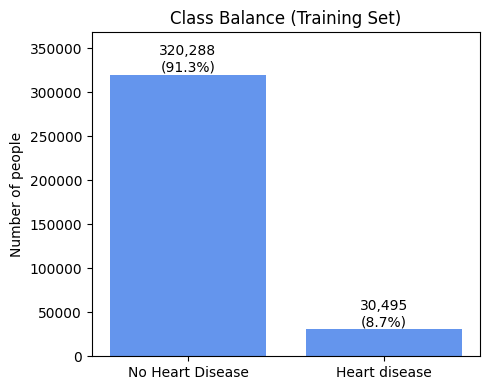

In [ ]:
import matplotlib.pyplot as plt

# Plot the class balance
counts = y_train.value_counts().sort_index()
labels = ['No Heart Disease', 'Heart disease']

plt.figure(figsize=(5, 4))
plt.bar(labels, counts.values, color='cornflowerblue')

for i, n in enumerate(counts.values):
    plt.text(i, n, f'{n:,}\n({n / len(y_train):.1%})', ha='center', va='bottom')

plt.ylim(0, counts.max() * 1.15)
plt.ylabel('Number of people')
plt.title('Class Balance (Training Set)')
plt.tight_layout()
plt.show()

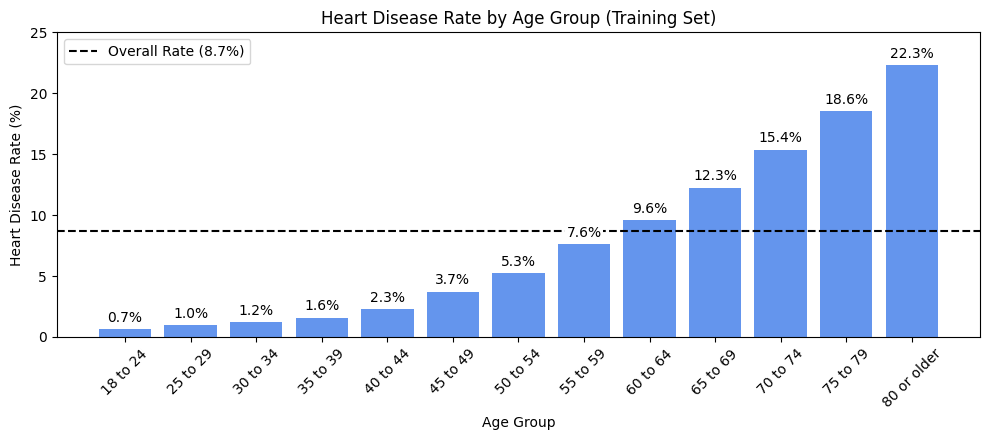

In [ ]:
# We've already encoded the features, but we want the original labels for the
# plots
raw_train = df.loc[X_train.index]

# For each age group, compute:
#  rate   = average of HeartDisease (0/1), which is the share with heart disease
#  people = number of people in the group
# reindex() puts the groups in age order (ORDINAL['AgeCategory'] is sorted),
# since groupby would otherwise sort them alphabetically
age_rate = (raw_train.groupby('AgeCategory')['HeartDisease']
            .agg(rate='mean', people='size')
            .reindex(ORDINAL['AgeCategory']))

# Bar chart of the heart disease rate for each age group
fig, ax = plt.subplots(figsize=(10, 4.5))

# Shorten labels: 'Age 65 to 69' -> '65 to 69'
bars = ax.bar(age_rate.index.str.replace('Age ', ''),
              # convert the rate to a percent
              age_rate['rate'] * 100,
              color='cornflowerblue')

# Write each bar's percentage just above
ax.bar_label(bars, fmt='%.1f%%', padding=3,
             bbox=dict(facecolor='white', edgecolor='none', pad=1))

# Dashed line at the overall rate, to see which groups are above or below
# average
ax.axhline(y_train.mean() * 100, color='black', linestyle='--',
           label=f'Overall Rate ({y_train.mean():.1%})')

ax.set_xlabel('Age Group')
ax.set_ylabel('Heart Disease Rate (%)')
ax.set_title('Heart Disease Rate by Age Group (Training Set)')

# Tilt the labels so they do not overlap
ax.tick_params(axis='x', rotation=45)

# Leave some room above the tallest bar for its label
ax.set_ylim(0, age_rate['rate'].max() * 100 * 1.12)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

The first plot reinforces the class balance calculated earlier (8.7% positive rate of the training set which reported CHD), so accuracy would be a misleading metric and the dummy baseline's PR-AUC is ~0.087.

The heart disease rate rises steadily with age, from 0.7% at 18–24 to 22.3% at 80 and older. Age is clearly related to the CHD, but how it compares with the other features is examined later.

## **Step 11:** Heart Disease Rate by Category
For each categorical column, compare the CHD rate across its values. Missing answers are left out of each rate (the fill from Step 9 is not used here), and the dashed line shows the overall rate. All plots use the training set only.

#### Helper Function For the Plots in This Section

In [ ]:
# The overall CHD rate, drawn as a dashed line on every chart
overall = y_train.mean() * 100

# Bar Chart of the CHD rate for each value of the column feature
# (NAN rows are skipped)
def plot_rate(ax, col, order=None, rotate=0):
    g = raw_train.groupby(col)['HeartDisease'].agg(rate='mean', people='size')

    # Put the values in their natural order if one is given
    if order is not None:
        g = g.reindex(order)
    rates = g['rate'] * 100

    ax.bar(range(len(g)), rates, color='cornflowerblue')
    ax.axhline(overall, color='grey', linestyle='--')

    # Write the rate above each bar
    for i, r in enumerate(rates):
        ax.text(i, r, f'{r:.1f}%', ha='center', va='bottom')

    # Leave 15% headroom so the labels are not cut off
    ax.set_ylim(0, rates.max() * 1.15)

    # Shorten long labels
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(v).split(' (')[0].replace(', Non-Hispanic', '')
        for v in g.index], rotation=rotate, ha='right' if rotate else 'center')
    ax.set_ylabel('Heart Disease Rate (%)')
    ax.set_title(col)
    return g

#### Sex, Race and Diabetes

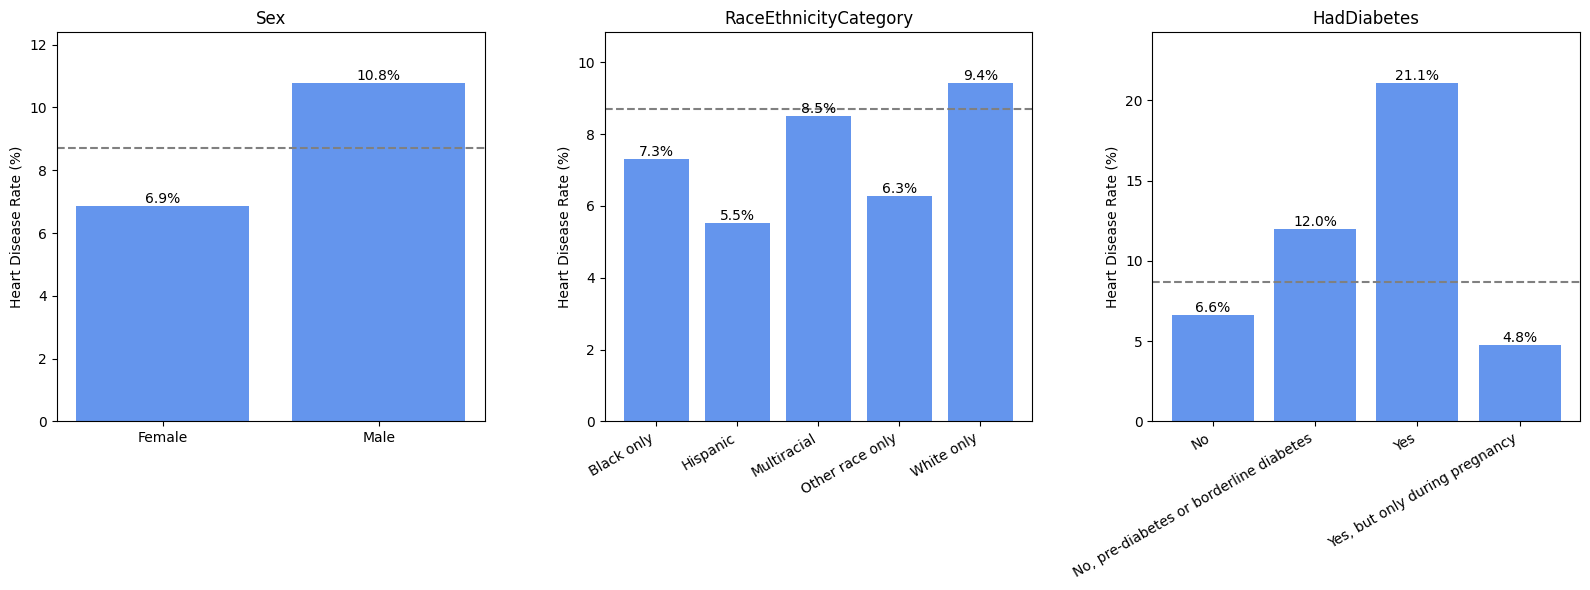

In [ ]:
# Three side-by-side charts (rotate the long labels on the second and third)
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, col, rot in zip(axes, ['Sex',
                               'RaceEthnicityCategory',
                               'HadDiabetes'],
                                [0, 30, 30]):
    plot_rate(ax, col, rotate=rot)
plt.tight_layout()
plt.show()

From the plots, men have a higher rate than women (10.8% vs. 6.9%), and diabetes is associated with ~3x the rate of no diabetes (21.1% vs. 6.6%). There's no clear trend looking at Race/Ethnicity in isolation, but there could be other factors (e.g. group ages) so we can't read anything into it yet.

#### Features with Ordered Categories

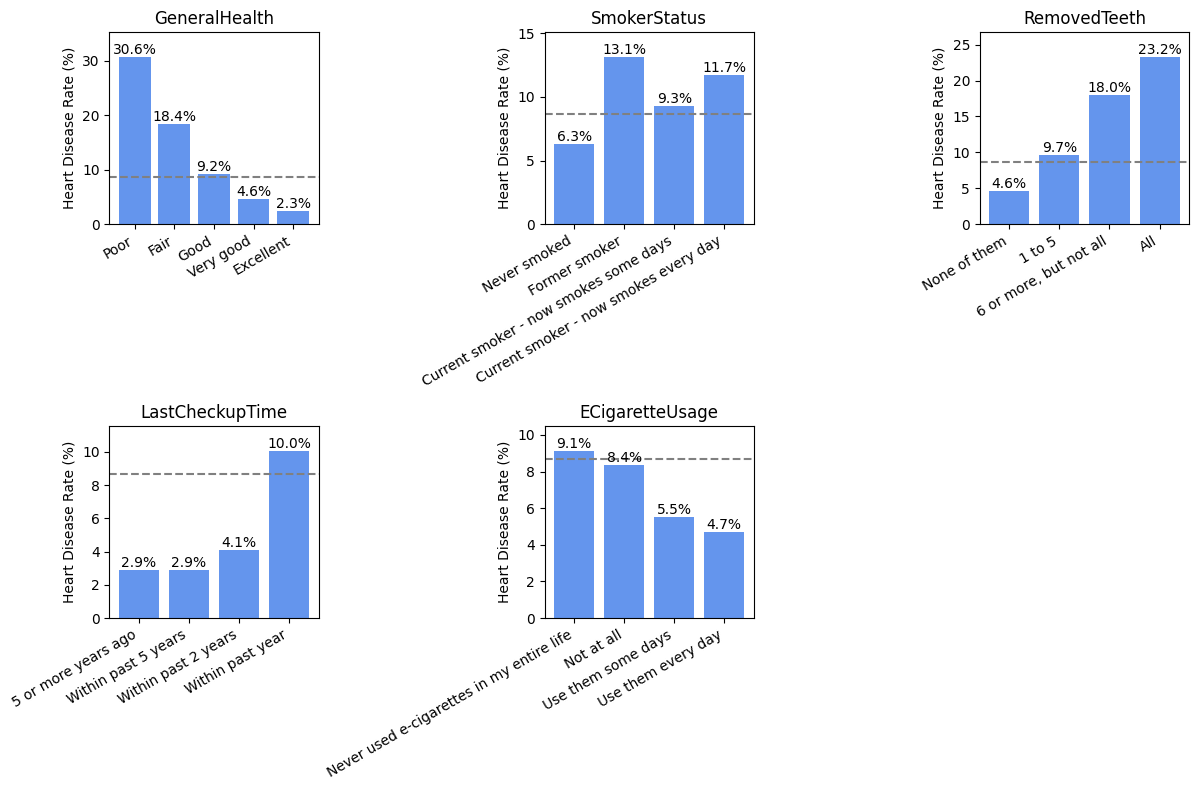

In [ ]:
# Columns whose categories have a natural order (the order comes from
# ORDINAL in Step 5)
ordered = ['GeneralHealth',
           'SmokerStatus',
           'RemovedTeeth',
           'LastCheckupTime',
           'ECigaretteUsage']

# 2 rows x 3 columns of charts; there are 5 columns,
# so hide the unused sixth axis
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ordered):
    plot_rate(ax, col, order=ORDINAL[col], rotate=30)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

The clearest trend is the self-reported health status which shows high rates of CHD with poorer health assessments. The surprising trend is the increased diesase rate with how many teeth someone had removed. Also, surprising is the use of E-cigarettes seems beneficial, but that could be due to the fact that younger individuals would tend to use E-cigarettes rather than the use actually lowers heart diesease.

####  The Yes/No Columns in One Chart

,No,Yes,percent Yes,difference
column,,,,
PhysicalActivities,13.6,7.2,76.3,-6.4
AlcoholDrinkers,11.3,6.5,53.1,-4.8
HighRiskLastYear,9.0,4.8,4.4,-4.2
HIVTesting,9.2,7.6,34.1,-1.6
HadDepressiveDisorder,8.1,10.8,20.6,2.7
HadAsthma,8.2,11.5,15.0,3.3
FluVaxLast12,6.5,10.8,52.5,4.3
DifficultyConcentrating,8.1,13.4,11.7,5.3
HadSkinCancer,8.0,16.5,8.0,8.5


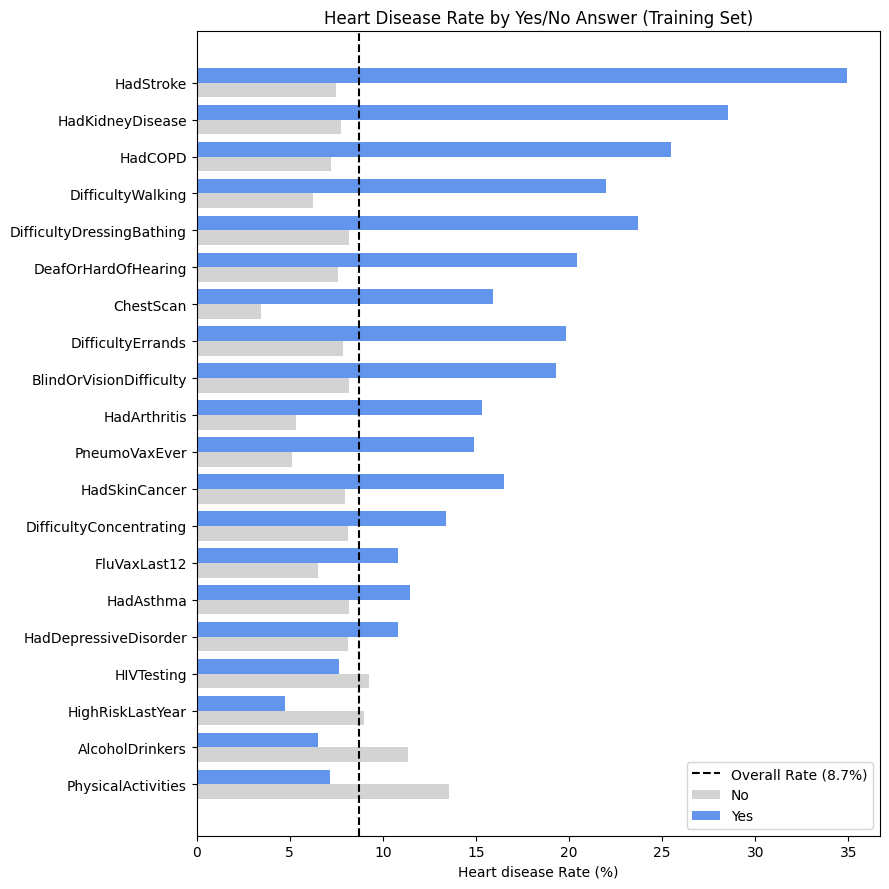

In [ ]:
import numpy as np

# For each Yes/No column we want the CHD rate when the answer is Yes vs No

# Rows with a missing answer are left out. Sex is excluded because the earlier
# chart covers it already
yes_no = [c for c in BINARY_COLS if c != 'Sex']

rows = []
for c in yes_no:
    # People who answered this question
    known = X_train[c].notna()
    rows.append({'column': c,
                 'No':  y_train[known & (X_train[c] == 0)].mean() * 100,
                 'Yes': y_train[known & (X_train[c] == 1)].mean() * 100,
                 'percent Yes': (X_train.loc[known, c] == 1).mean() * 100})

yn = pd.DataFrame(rows).set_index('column')

# How much higher the rate is for Yes
yn['difference'] = yn['Yes'] - yn['No']

# Sort to put the largest difference at the top of the chart
yn = yn.sort_values('difference')
display(yn.round(1))

# Horizontal bars: gray for No, blue for Yes, one pair per column
pos = np.arange(len(yn))
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(pos - 0.2, yn['No'], height=0.4, color='lightgray', label='No')
ax.barh(pos + 0.2, yn['Yes'], height=0.4, color='cornflowerblue', label='Yes')
ax.axvline(overall,
           color='black',
           linestyle='--',
           label=f'Overall Rate ({overall:.1f}%)')
ax.set_yticks(pos)
ax.set_yticklabels(yn.index)
ax.set_xlabel('Heart disease Rate (%)')
ax.set_title('Heart Disease Rate by Yes/No Answer (Training Set)')
ax.legend()
plt.tight_layout()
plt.show()

CHD rates differ the most for existing conditions: stroke (35.0% vs. 7.5%), kidney disease, COPD, and difficulty walking are all associated with rates 3-4x higher. Physical activity, alcohol use and the high-risk-behavior question show lower rates for "Yes", which most likely reflects the person's age (i.e. those groups are younger) and not a benefical effect. These are unadjusted rates, so the model coefficients determined later are needed to compare features fairly.

## **Step 12:** Explore the Numeric Columns
Look at the distribution of each numeric column and compare it between people with and without CHD. Missing values are left out of each plot, and all plots use the training data only.

#### Box Plots by Outcome

,count,mean,std,min,1%,50%,99%,max
PhysicalHealthDays,342480.0,4.3,8.6,0.0,0.0,0.0,30.0,30.0
MentalHealthDays,343917.0,4.4,8.4,0.0,0.0,0.0,30.0,30.0
SleepHours,346770.0,7.0,1.5,1.0,3.0,7.0,12.0,24.0
HeightInMeters,328526.0,1.7,0.1,0.9,1.5,1.7,1.9,2.4
WeightInKilograms,317922.0,83.1,21.4,22.7,46.4,80.7,147.4,290.3
BMI,312623.0,28.5,6.6,12.0,17.8,27.4,49.5,99.6


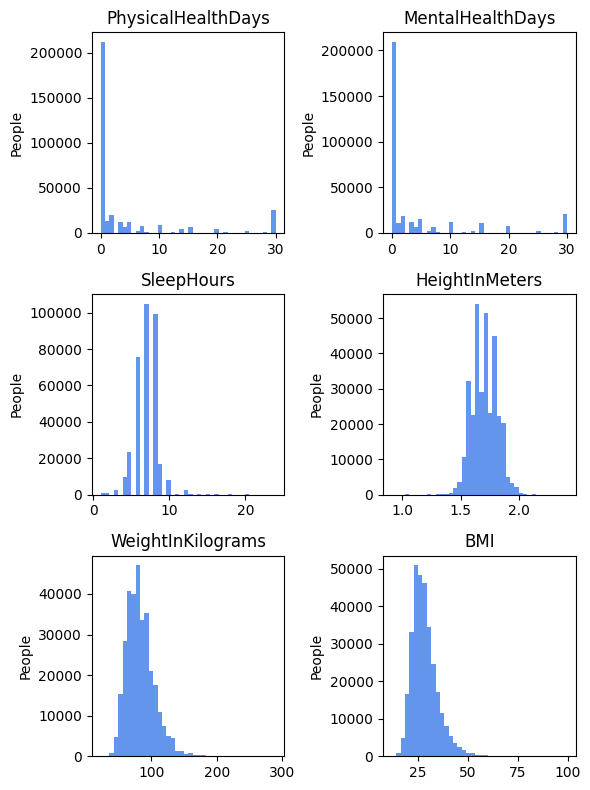

In [ ]:
# Summary of each numeric column (1% and 99% show where the extremes start)
display(X_train[NUMERIC_COLS].describe(percentiles=[.01, .5, .99]).round(1).T)

# One histogram per column
fig, axes = plt.subplots(3, 2, figsize=(6, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.hist(X_train[col].dropna(), bins=40, color='cornflowerblue')
    ax.set_title(col)
    ax.set_ylabel('People')
plt.tight_layout()
plt.show()

#### Medians and the Extreme Values

In [ ]:
# Median of each column for Yes vs No
medians = X_train[NUMERIC_COLS].groupby(y_train).median().T
medians.columns = ['No', 'Yes']
display(medians.round(1))

# The health days columns are the number of bad days in the last 30
for c in ['PhysicalHealthDays', 'MentalHealthDays']:
    answered = X_train[c].notna().mean()
    print(f'{c}: {(X_train[c] == 0).mean() / answered:.0%} answered 0, '
          f'{(X_train[c] == 30).mean() / answered:.0%} answered 30')

# How many extreme values are there
print('BMI above 50:', (X_train['BMI'] > 50).sum())
print('Sleep 3 hours or less, or 14 or more:',
      ((X_train['SleepHours'] <= 3) | (X_train['SleepHours'] >= 14)).sum())

,No,Yes
PhysicalHealthDays,0.0,2.0
MentalHealthDays,0.0,0.0
SleepHours,7.0,7.0
HeightInMeters,1.7,1.7
WeightInKilograms,79.4,83.9
BMI,27.4,28.3


PhysicalHealthDays: 62% answered 0, 7% answered 30
MentalHealthDays: 61% answered 0, 6% answered 30
BMI above 50: 2856
Sleep 3 hours or less, or 14 or more: 5696


The two health day columns are concentrated at 0 (about 61–62%) and 30 (6–7%), so that data is not Gaussian; therefore, a log transform would not help. BMI and weight have long right tails (BMI up to 99.6), and sleep hours include a few implausible values (up to 24). These values are kept because they are possible or rare, and i'll test if models are sensitive to them.

## **Step 13:** Correlations
Check which features are related to each other (redundancy) and to the CHD target. The ordered categories are converted to numbers in their natural order, and the 0/1 columns are used as-is. The unordered categories (state, race, diabetes type, tetanus, COVID) are left out, because a correlation with a label code doesn't have a meaning. Missing values are skipped pair-by-pair.

#### Build the Correlation Matrix

In [ ]:
# Numeric, 0/1 and ordered columns. The ordered ones are text, so convert them
# to numbers (0, 1, 2, ...) using the category order from Step 5
corr_cols = NUMERIC_COLS + BINARY_COLS + list(ORDINAL)
corr_data = X_train[corr_cols].copy()

for col, categories in ORDINAL.items():
    corr_data[col] = corr_data[col].map(
        {v: i for i, v in enumerate(categories)})

# Add the target so we can also see each feature's correlation to it
corr_data['HeartDisease'] = y_train

# Correlation matrix (missing values are skipped pair by pair)
corr = corr_data.corr()
print(corr.shape)

(34, 34)


#### The Heatmap

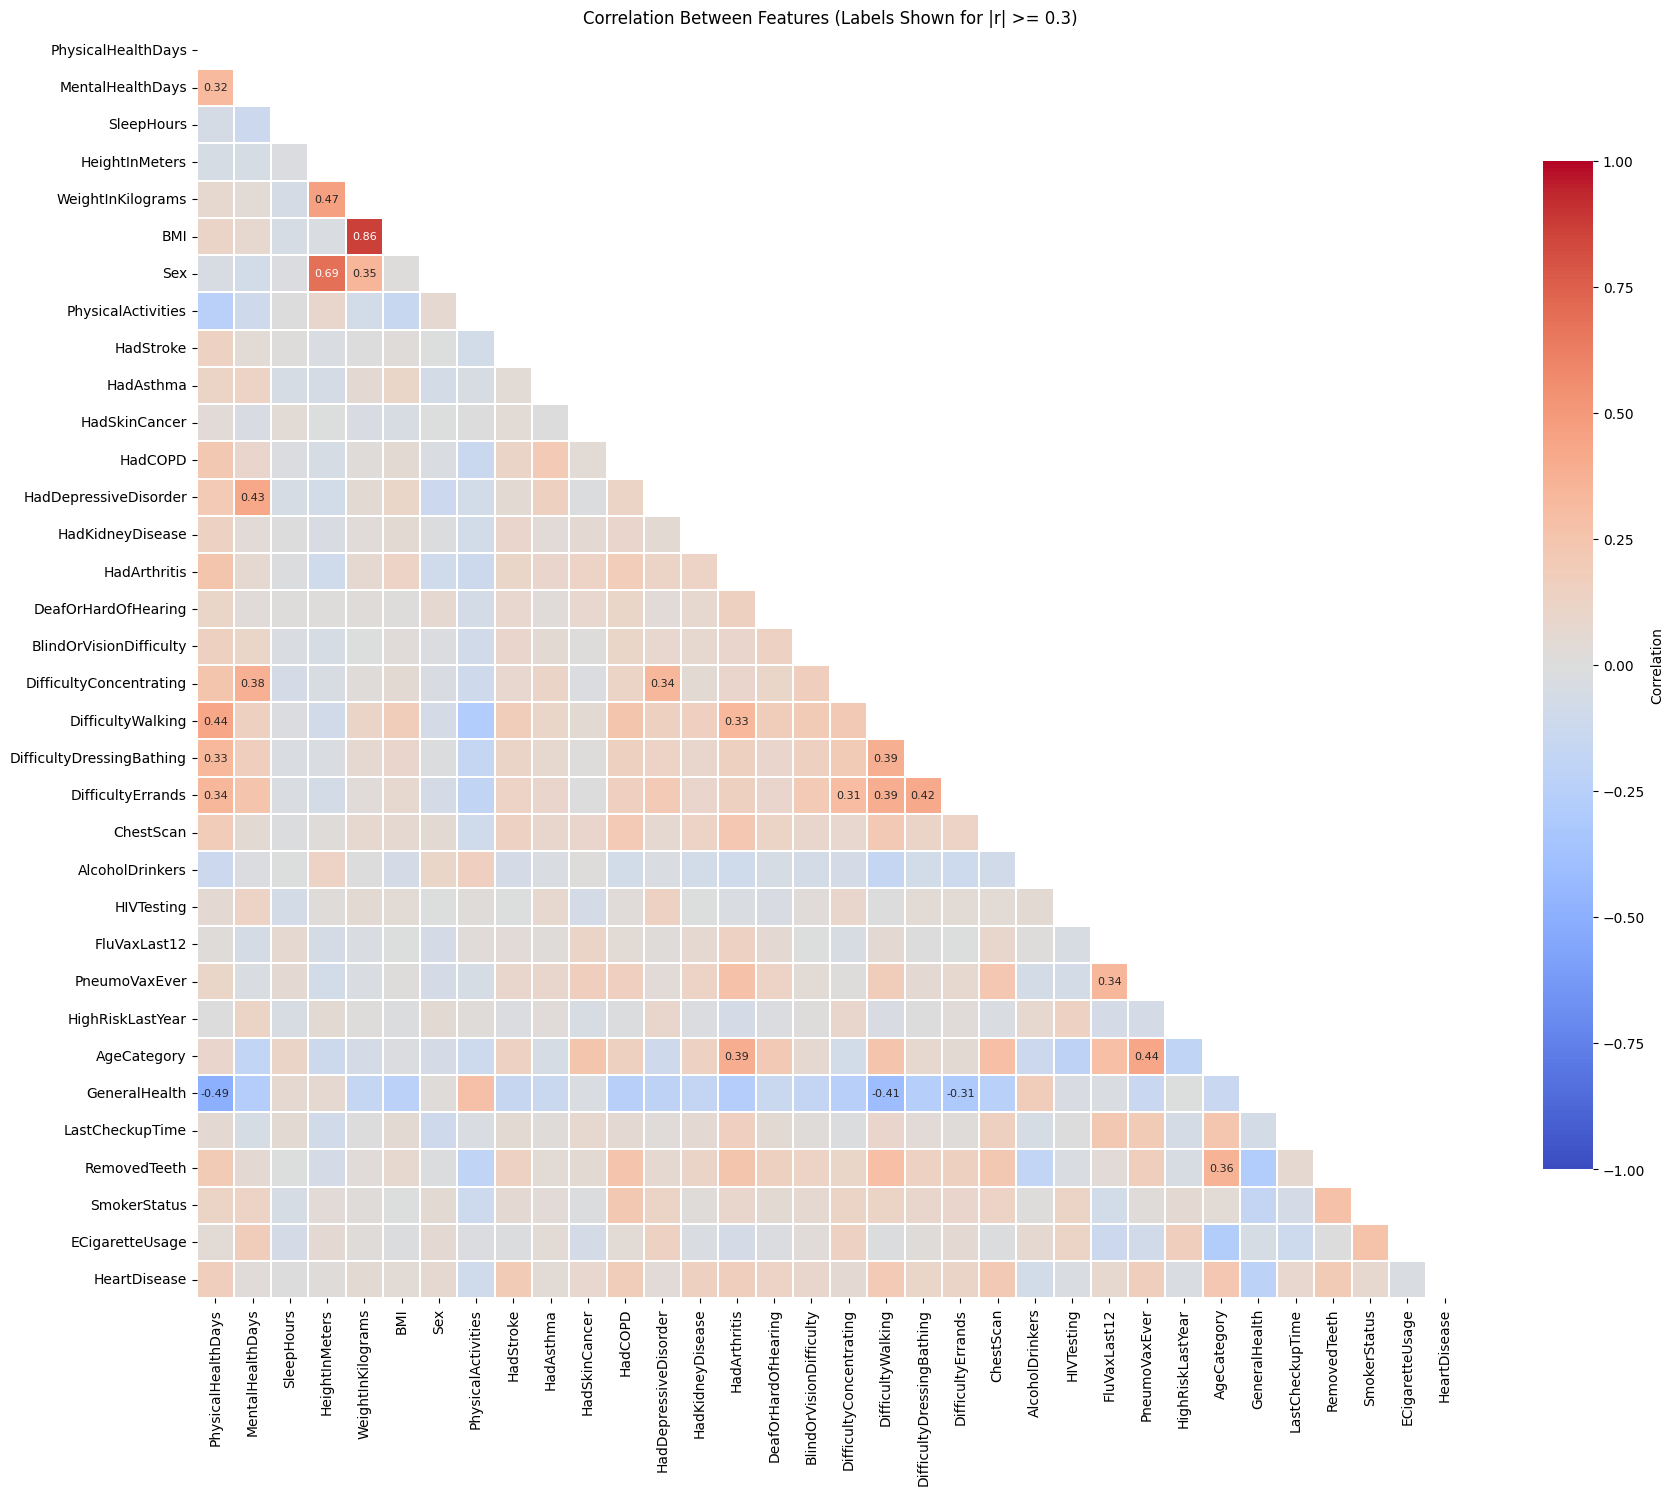

In [ ]:
import seaborn as sns

# Hide the upper triangle as it just repeats the data
mask = np.triu(np.ones_like(corr, dtype=bool))

# Only write the number on squares with a correlation of at least 0.3
# (in either direction), so the plot stays readable
LABEL_THRESHOLD = 0.3
labels = corr.round(2).astype(str).where(corr.abs() >= LABEL_THRESHOLD, '')

plt.figure(figsize=(18, 16))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            annot=labels, fmt='',
            annot_kws={'size': 8},
            square=True, linewidths=0.3,
            cbar_kws={'label': 'Correlation', 'shrink': 0.7})
plt.title('Correlation Between Features (Labels Shown for |r| >= ' +
          f'{LABEL_THRESHOLD})')
plt.tight_layout()
plt.show()

#### Correlation with the Target, and the Strongest Pairs

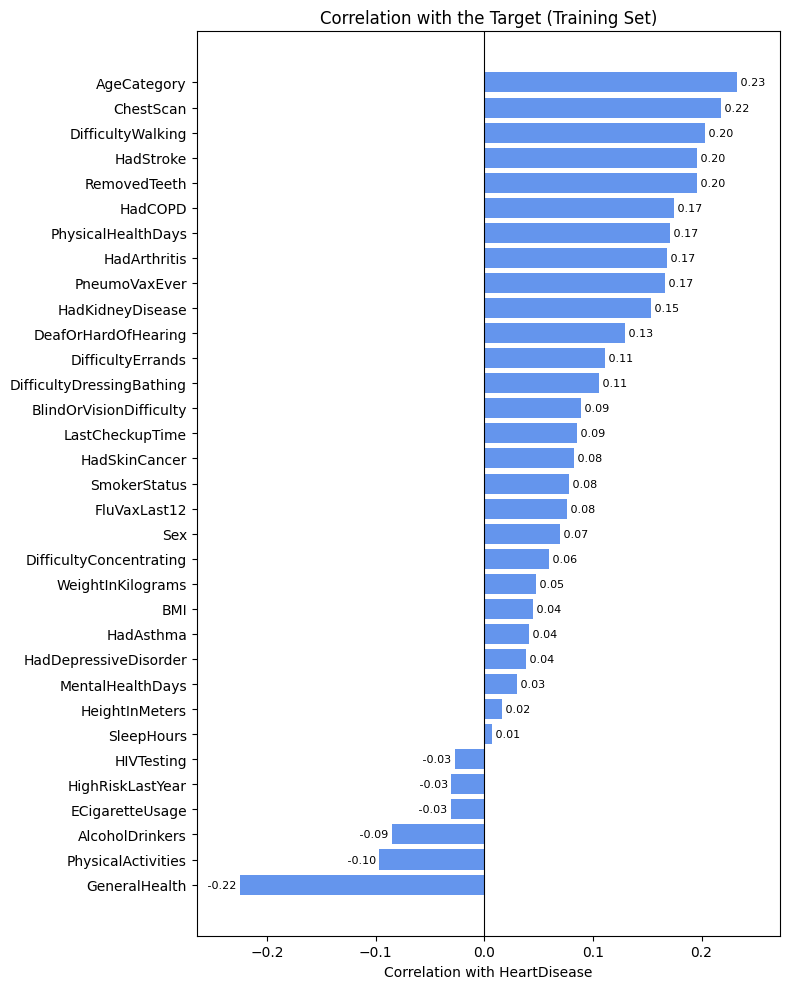

,,correlation
BMI,WeightInKilograms,0.86
Sex,HeightInMeters,0.69
GeneralHealth,PhysicalHealthDays,-0.49
WeightInKilograms,HeightInMeters,0.47
DifficultyWalking,PhysicalHealthDays,0.44
AgeCategory,PneumoVaxEver,0.44
HadDepressiveDisorder,MentalHealthDays,0.43
DifficultyErrands,DifficultyDressingBathing,0.42
GeneralHealth,DifficultyWalking,-0.41


In [ ]:
# Sorted correlation of each feature with CHD
with_target = corr['HeartDisease'].drop('HeartDisease').sort_values()

plt.figure(figsize=(8, 10))
plt.barh(with_target.index, with_target.values, color='cornflowerblue')

# Write the correlation at the end of each bar
# (to the right of positive bars and to the left of negative ones)
for i, r in enumerate(with_target.values):
    plt.text(r, i, f' {r:.2f} ', va='center',
             ha='left' if r >= 0 else 'right', fontsize=8)

plt.axvline(0, color='black', linewidth=0.8)

# Widen the x-axis a little so the labels are not cut off
plt.xlim(with_target.min() - 0.04, with_target.max() + 0.04)
plt.xlabel('Correlation with HeartDisease')
plt.title('Correlation with the Target (Training Set)')
plt.tight_layout()
plt.show()

# Feature pairs with a correlation of 0.4 or more (in either direction).
# The mask keeps each pair once, and the CHD target is left out
pairs = corr.where(~mask).stack()
pairs = pairs.drop(labels=[i for i in pairs.index if 'HeartDisease' in i])
strong = pairs[pairs.abs() >= 0.4].sort_values(key=abs, ascending=False)
display(strong.round(2).rename('correlation').to_frame())

No feature has a strong linear correlation with CHD: the highest are age (0.23), chest scan (0.22), difficulty walking and stroke (0.20), and general health (−0.22). Among the features, the main redundancy is BMI with weight (0.86), and a cluster of health-status questions (general health, physical health days, difficulty walking) is moderately correlated (0.41–0.49). Nothing approaches the near-duplicates, so I will keep all features for the first set of model evaluations and test dropping weight and height in favor of BMI as an experiment later.

## **Step 14:** Principal Component Analysis (PCA)
A PCA study is mostly exploratory here. The analysis uses the filled training data, which is standardized. PCA is ultimately not used for the models so I can keep the original columns so that the results stay understandable.

#### Explained Variance

,variance explained,cumulative
PC1,0.331,0.331
PC2,0.227,0.558
PC3,0.168,0.726
PC4,0.157,0.883
PC5,0.114,0.997
PC6,0.003,1.000


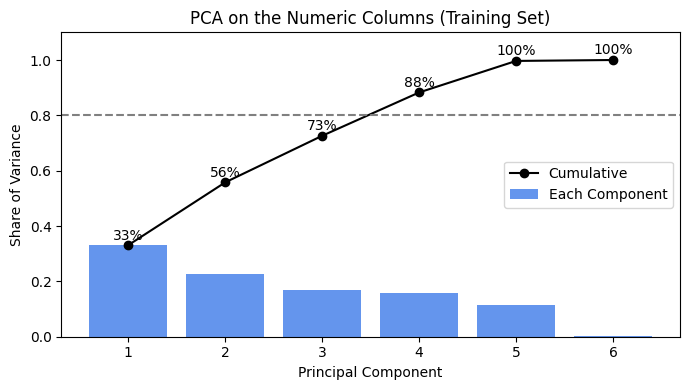

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the six numeric columns (mean 0, std 1) so that no column
# dominates because of its units. Then the PCA fit.
scaler = StandardScaler()
scaled = scaler.fit_transform(train_filled[NUMERIC_COLS])
pca = PCA()
pcs = pca.fit_transform(scaled)

# Share of the total variance explained by each component, as well as the
# running total
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
display(pd.DataFrame({'variance explained': explained.round(3),
                      'cumulative': cumulative.round(3)},
                     index=[f'PC{i + 1}' for i in range(len(explained))]))

# Bars for each component, line to follow the cumulative total, and a dashed
# line at see when 80% is reached
x = np.arange(1, len(explained) + 1)
plt.figure(figsize=(7, 4))
plt.bar(x, explained, color='cornflowerblue', label='Each Component')
plt.plot(x, cumulative, 'o-', color='black', label='Cumulative')
for i, c in enumerate(cumulative):
    plt.text(x[i], c + 0.02, f'{c:.0%}', ha='center')
plt.axhline(0.8, color='gray', linestyle='--')
plt.ylim(0, 1.1)
plt.xlabel('Principal Component')
plt.ylabel('Share of Variance')
plt.title('PCA on the Numeric Columns (Training Set)')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

#### Loadings (What Each Component Indicates)

In [ ]:
# How the features and each principal component are related
loadings = pd.DataFrame(pca.components_[:3].T, index=NUMERIC_COLS,
                        columns=['PC1', 'PC2', 'PC3'])
display(loadings.round(2))

,PC1,PC2,PC3
PhysicalHealthDays,0.15,0.61,-0.03
MentalHealthDays,0.12,0.64,0.14
SleepHours,-0.10,-0.28,-0.58
HeightInMeters,0.29,-0.33,0.69
WeightInKilograms,0.70,-0.15,-0.02
BMI,0.62,0.02,-0.41


#### First Two Components, Colored by Outcome

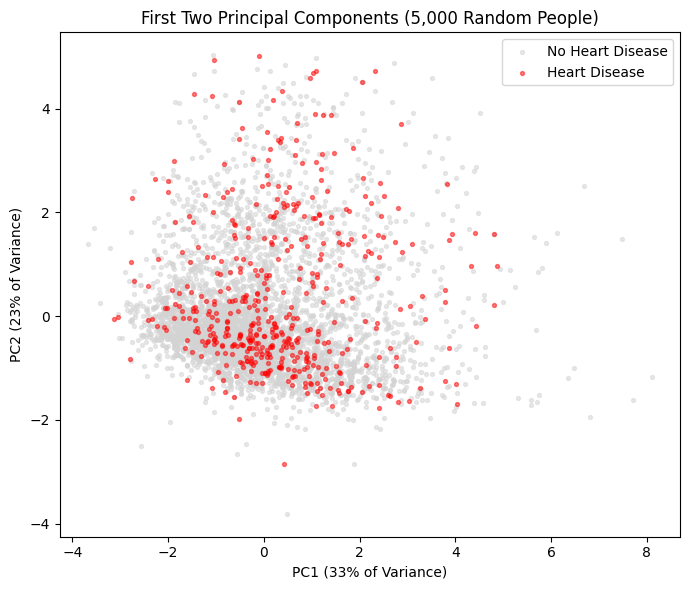

In [ ]:
# Plot 5,000 random people (350,000 points makes the plot hard to read)
rng = np.random.default_rng(42)
sample = rng.choice(len(pcs), size=5000, replace=False)

plt.figure(figsize=(7, 6))
for value, color, label in [(0, 'lightgray', 'No Heart Disease'),
                            (1, 'red', 'Heart Disease')]:
    pick = sample[y_train.values[sample] == value]
    plt.scatter(pcs[pick, 0],
                pcs[pick, 1],
                s=8,
                alpha=0.5,
                color=color,
                label=label)
plt.xlabel(f'PC1 ({explained[0]:.0%} of Variance)')
plt.ylabel(f'PC2 ({explained[1]:.0%} of Variance)')
plt.title('First Two Principal Components (5,000 Random People)')
plt.legend()
plt.tight_layout()
plt.show()

Four of the six components reach 88% of the variance. PC1 reflects body size (weight, BMI, height) and PC2 reflects bad health days. People with CHD lean toward higher PC2 but overlap heavily with everyone else, consistent with the weak single-column results. PCA is used only for exploration. The models will use the original features so the coefficients are understandable.

## **Step 15:** Modeling Setup
This cell builds every model using this pipline: fill in missing values -> encode and scale -> build model. The models are evaluated with the same 5-fold stratified cross-validation on the training data set. The pipeline is refit inside each fold so the fill values and scaling come only from that fold's training rows.

Metrics: ROC-AUC and PR-AUC (predicted probabilities), recall, precision and F1 (using the default 0.5 cutoff), and the Brier score (probability accuracy where lower is better). Accuracy is left out because predicting "no CHD" for everyone already scores 91%.

#### Preprocessing and Pipeline Builders

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

def build_preprocess(drop=()):
    # Encode and scale each column group. Columns in `drop` are left out
    keep = lambda cols: [c for c in cols if c not in drop]
    ord_keep = keep(list(ORDINAL))

    return ColumnTransformer([
        # Standardize numeric columns
        ('num', StandardScaler(), keep(NUMERIC_COLS)),

        # Number the ordered categories in their natural order,
        # then standardize
        ('ord', Pipeline([('enc',
                           OrdinalEncoder(categories=[ORDINAL[c]
                                                      for c in ord_keep])),
                          ('scale', StandardScaler())]), ord_keep),

        # One 0/1 column per category for the unordered categories
        ('nom', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False),
                              keep(NOMINAL_COLS)),

        # 0/1 columns pass through unchanged
        ('bin', 'passthrough', keep(BINARY_COLS)),

    ])

def make_model(clf, drop=()):
    # Full pipeline: fill missing values -> encode/scale -> classifier
    return Pipeline([('impute', SurveyImputer()),
                     ('prep', build_preprocess(drop)),
                     ('clf', clf)])

#### Cross-Validation and the Evaluation Function

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score
import time

# Ensure the 5 stratified folds keeps the ~8.7% positive rate. The same folds
# are used for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# zero_division = 0 avoids a warning for models that never predict a
# positive (the dummy)
scoring = {'roc_auc': 'roc_auc',
           'pr_auc': 'average_precision',
           'recall': 'recall',
           'precision': make_scorer(precision_score, zero_division=0),
           'f1': make_scorer(f1_score, zero_division=0),
           'brier': 'neg_brier_score'}

# Cross-validate one model and return the mean of each metric
# n: optional number of training rows to use
# (for models too slow to use all of the rows)
def evaluate(name, model, n=None):
    t = time.time()
    Xs, ys = X_train, y_train

    if n:
        # Stratified subsample so the ~8.7% positive rate is kept
        Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=n,
                                        stratify=y_train, random_state=42)

    res = cross_validate(model, Xs, ys, cv=cv, scoring=scoring, n_jobs=-1)
    out = {'Model': name, 'rows': len(Xs)}

    for key in scoring:
        s = res[f'test_{key}']

        # Flip the Brier sign back
        out[key] = round((-s if key == 'brier' else s).mean(), 3)

    # Spread across the 5 folds
    out['ROC-AUC std'] = round(res['test_roc_auc'].std(), 3)
    out['seconds'] = round(time.time() - t)
    return out

#### Test the Workflow - Baseline and Logistic Regression

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

results = []
# Baseline where we predict the overall rate (8.7%) for everyone
results.append(evaluate('Dummy (Base Rate)',
                        make_model(DummyClassifier(strategy='prior'))))

# Test the Logistic Regression model
results.append(evaluate('Logistic Regression',
                        make_model(LogisticRegression(max_iter=1000))))

display(pd.DataFrame(results))

,Model,rows,roc_auc,pr_auc,recall,precision,f1,brier,ROC-AUC std,seconds
0,Dummy (Base Rate),350783,0.500,0.087,0.000,0.000,0.000,0.079,0.000,4
1,Logistic Regression,350783,0.846,0.356,0.119,0.546,0.196,0.066,0.002,7


## **Step 16:** Evalulate 10 ML Models
All the models will use the same pipeline, the same 5 stratified folds, and the same output metrics. Initial settings are reasonable defaults, not tuned, and the experiments in the next section test the model choices.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# (name, model, number of rows to use or None for all)
models = [
    ('Dummy (base rate)',
     make_model(DummyClassifier(strategy='prior')), None),

    ('Logistic Regression (L2)',
     make_model(LogisticRegression(max_iter=1000)), None),

    ('Logistic Regression (L1)',
     make_model(LogisticRegression(penalty='l1',
                                   solver='liblinear', C=0.1)), None),

    # A subsample is used for KNN because it was taking a VERY long time to use
    # all the data
    ('KNN (k=50)',
     make_model(KNeighborsClassifier(n_neighbors=50)), 80000),

    ('Decision Tree (Depth 6)',
     make_model(DecisionTreeClassifier(max_depth=6,
                                      min_samples_leaf=100,
                                      random_state=42)),
                                      None),

    ('Random Forest',
     make_model(RandomForestClassifier(n_estimators=100,
                                       min_samples_leaf=50,
                                       n_jobs=-1,
                                       random_state=42)),
                                       None),

    ('Gradient Boosting (Histogram)',
    make_model(HistGradientBoostingClassifier(random_state=42)), None),

    ('Naive Bayes',
     make_model(GaussianNB()), None),

    # A subsample is used for SVM because it was taking a VERY long time to use
    # all the data
    ('SVM (RBF)',
     make_model(SVC(C=1.0,
                    kernel='rbf',
                    probability=True,
                    random_state=42)),
                    30000),

    ('MLP (32, 16)',
     make_model(MLPClassifier(hidden_layer_sizes=(32, 16),
                              alpha=1e-3,
                              early_stopping=True,
                              max_iter=100,
                              random_state=42)), None),
]

results = []
for name, model, n in models:
    results.append(evaluate(name, model, n))
    # Progress note, since this cell takes a while to run
    print('Done:', name)

results_df = pd.DataFrame(results).set_index('Model')
display(results_df.sort_values('roc_auc', ascending=False))

Done: Dummy (base rate)
Done: Logistic Regression (L2)
Done: Logistic Regression (L1)
Done: KNN (k=50)
Done: Decision Tree (Depth 6)
Done: Random Forest
Done: Gradient Boosting (Histogram)
Done: Naive Bayes
Done: SVM (RBF)
Done: MLP (32, 16)


,rows,roc_auc,pr_auc,recall,precision,f1,brier,ROC-AUC std,seconds
Model,,,,,,,,,
Gradient Boosting (Histogram),350783,0.848,0.359,0.091,0.569,0.156,0.066,0.002,30
Logistic Regression (L2),350783,0.846,0.356,0.119,0.546,0.196,0.066,0.002,6
"MLP (32, 16)",350783,0.846,0.356,0.093,0.572,0.159,0.066,0.001,21
Logistic Regression (L1),350783,0.846,0.356,0.118,0.548,0.194,0.066,0.002,71
Random Forest,350783,0.846,0.353,0.007,0.688,0.014,0.067,0.001,49
Decision Tree (Depth 6),350783,0.825,0.310,0.034,0.599,0.064,0.068,0.002,6
KNN (k=50),80000,0.808,0.282,0.005,0.608,0.009,0.070,0.006,24
Naive Bayes,350783,0.778,0.266,0.629,0.213,0.318,0.217,0.002,4
SVM (RBF),30000,0.726,0.273,0.008,0.589,0.017,0.073,0.014,327


There are 5 models which tie for the best performing model (ROC-AUC 0.846–0.848, PR-AUC 0.353–0.359): Gradient Boosting, Logistic Regression, the MLP and the Random Forest. The fold-to-fold spread (0.001–0.002) is as large as the gaps between the top performing models. The simple logistic regression matches the performance of the more complex models, which suggests the signal in these survey answers is mostly additive and that the features, not the model choice, set the ceiling in terms of performance. The decision tree (0.825) is weaker, and Naive Bayes has badly calibrated probabilities (Brier is 0.217, which is worse than the 0.079 baseline). KNN and the RBF SVM were run on subsamples because they were taking a VERY long time to train, so their lower scores should not be evaluated as a fair comparison. Recall is low at the default 0.5 cutoff for most models because the probabilities are conservative; therefore, the final model threshold will be chosen later.

## **Step 17:** Experiments

### **Experiment 1:** Handling the Class Imbalance
Only 8.7% of people surveyed have CHD. This experiment asks whether reweighting or resampling the classes helps improve the model. Three options are compared for Logistic Regression and Gradient Boosting:
- No adjustment
- Class weights (errors on heart disease cases count more)
- Undersampling (random negatives are dropped from each training fold until the classes are balanced).

Undersampling happens inside the pipeline, so it only changes the training part of each fold, and the validation folds keep the positive CHD rate of 8.7%.

In [ ]:
# Install the imbalance-learn module
!pip install -q imbalanced-learn

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

# Same pipeline as make_model, with random undersampling of the majority class
# after preprocessing. It only acts when fitting, so validation folds stay
# untouched.
def make_model_undersampled(clf, drop=()):
    return ImbPipeline([('impute', SurveyImputer()),
                        ('prep', build_preprocess(drop)),
                        ('under', RandomUnderSampler(random_state=42)),
                        ('clf', clf)])

experiments = [
    ('Logistic Regression | None',
     make_model(LogisticRegression(max_iter=1000))),
    ('Logistic Regression | Class Weights',
     make_model(LogisticRegression(max_iter=1000, class_weight='balanced'))),
    ('Logistic Regression | Undersampling',
     make_model_undersampled(LogisticRegression(max_iter=1000))),
    ('Gradient Boosting | None',
     make_model(HistGradientBoostingClassifier(random_state=42))),
    ('Gradient Boosting | Class Weights',
     make_model(HistGradientBoostingClassifier(class_weight='balanced',
                                               random_state=42))),
    ('Gradient Boosting | Undersampling',
     make_model_undersampled(HistGradientBoostingClassifier(random_state=42))),
]

exp1 = pd.DataFrame([evaluate(name, model) for name,
                     model in experiments]).set_index('Model')
display(exp1.drop(columns='rows'))

,roc_auc,pr_auc,recall,precision,f1,brier,ROC-AUC std,seconds
Model,,,,,,,,
Logistic Regression | None,0.846,0.356,0.119,0.546,0.196,0.066,0.002,7
Logistic Regression | Class Weights,0.846,0.356,0.782,0.233,0.359,0.164,0.002,7
Logistic Regression | Undersampling,0.846,0.355,0.783,0.232,0.358,0.165,0.002,4
Gradient Boosting | None,0.848,0.359,0.091,0.569,0.156,0.066,0.002,30
Gradient Boosting | Class Weights,0.849,0.359,0.807,0.225,0.352,0.164,0.002,28
Gradient Boosting | Undersampling,0.847,0.352,0.809,0.223,0.349,0.168,0.002,12


Class weights and undersampling leave the ranking of people essentially unchanged (ROC-AUC 0.846–0.849, PR-AUC 0.352–0.359). The recall rises from ~0.1 to ~0.8 and precision falls from ~0.55 to ~0.23. They also inflate the predicted probabilities, so the Brier score worsens from 0.066 to ~0.165 (which is worse than the 0.079 baseline). Because the goal of this study is a calibrated probability, the final model is trained without reweighting or resampling.

## **Experiment 2:** Which Features Matter?
This experiment removes groups of features and checks how much the scores change. Each version is tested with Logistic Regression and Gradient Boosting.

- **BMI Only:** We drop the height and weight, because BMI is calculated from these quantities.
- **No Weak Features:** We drop the vaccination, HIV testing, COVID and high-risk questions, which have no obvious link to CHD and are missing the most in the data set.
- **No State:** We drop the state column.
- **No Consequence Features:** We drop general health, physical health days, difficulty walking, difficulty with dressing/bathing, difficulty with errands, chest scan, stroke and last checkup time. These can be a result of existing CHD more than a cause, so this shows how much of the performance is derived from them.
- **No Race:** We drop the race/ethnicity.
- **Slim:** We put BMI only and remove weak features and state in the model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Column groups to remove
weak = ['HIVTesting', 'HighRiskLastYear', 'CovidPos',
        'TetanusLast10Tdap', 'PneumoVaxEver', 'FluVaxLast12']
consequences = ['GeneralHealth', 'PhysicalHealthDays', 'DifficultyWalking',
                'DifficultyDressingBathing', 'DifficultyErrands', 'ChestScan',
                'HadStroke', 'LastCheckupTime']
slim_drop = ['HeightInMeters', 'WeightInKilograms', 'State',
             'RaceEthnicityCategory'] + weak

# Name -> list of columns to drop (empty list = keep everything)
feature_sets = {
    'All features': [],
    'BMI only (no height/weight)': ['HeightInMeters', 'WeightInKilograms'],
    'No weak features': weak,
    'No State': ['State'],
    'No consequence features': consequences,
    'No race': ['RaceEthnicityCategory'],
    'Slim (BMI only, no weak, no State)': slim_drop,
}

classifiers = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=1000),
    'Gradient Boosting':
        lambda: HistGradientBoostingClassifier(random_state=42),
}

rows = []
for clf_name, make_clf in classifiers.items():
    for set_name, drop in feature_sets.items():
        # make_model(..., drop=...) leaves those columns out of the
        # preprocessing
        r = evaluate(f'{clf_name} | {set_name}',
                     make_model(make_clf(), drop=drop))
        # Number of features kept
        r['features'] = len(X_train.columns) - len(set(drop))
        rows.append(r)
        print('Done:', r['Model'])

exp2 = pd.DataFrame(rows).set_index('Model')
display(exp2[['features', 'roc_auc', 'pr_auc', 'brier', 'ROC-AUC std']])

Done: Logistic Regression | All features
Done: Logistic Regression | BMI only (no height/weight)
Done: Logistic Regression | No weak features
Done: Logistic Regression | No State
Done: Logistic Regression | No consequence features
Done: Logistic Regression | No race
Done: Logistic Regression | Slim (BMI only, no weak, no State)
Done: Gradient Boosting | All features
Done: Gradient Boosting | BMI only (no height/weight)
Done: Gradient Boosting | No weak features
Done: Gradient Boosting | No State
Done: Gradient Boosting | No consequence features
Done: Gradient Boosting | No race
Done: Gradient Boosting | Slim (BMI only, no weak, no State)


,features,roc_auc,pr_auc,brier,ROC-AUC std
Model,,,,,
Logistic Regression | All features,38,0.846,0.356,0.066,0.002
Logistic Regression | BMI only (no height/weight),36,0.846,0.356,0.066,0.002
Logistic Regression | No weak features,32,0.845,0.356,0.066,0.002
Logistic Regression | No State,37,0.846,0.356,0.066,0.002
Logistic Regression | No consequence features,30,0.821,0.306,0.069,0.002
Logistic Regression | No race,37,0.845,0.355,0.066,0.002
"Logistic Regression | Slim (BMI only, no weak, no State)",28,0.845,0.354,0.066,0.002
Gradient Boosting | All features,38,0.848,0.359,0.066,0.002
Gradient Boosting | BMI only (no height/weight),36,0.849,0.360,0.066,0.002


As seen above, removing height and weight, the six vaccination, testing and COVID questions, and the state or race columns changes ROC-AUC by 0.001 or less for both Logistic Regression and Gradient Boosting. A slim set of 29 features performs the same as all 38 (ROC-AUC 0.845 or 0.848). Removing the consequence features (general health, physical health days, chest scan, stroke, difficulty walking, dressing/bathing and errands, and last checkup time) is the only change that impacts model performance where ROC-AUC falls by ~0.025 (to 0.821–0.823) and PR-AUC by about 0.05 (to 0.306–0.310). Therefore, part of the model's accuracy comes from variables that can reflect existing illness, not from risk factors alone, so this reinforces that the full model should be read as screening for current disease, not as a prediction of future CHD risk.

## **Experiment 3:** Tuning the Tree Ensembles
The first evaluation used default settings for the tree models. This experiment checks whether stronger or weaker regularization changes the Random Forest (RF) and Gradient Boosting (GB). The key settings are how small a leaf may be for the forest, tree size, learning rate, and number of rounds for boosting. For each setting the validation PR-AUC is compared with the training PR-AUC: a large gap means the model is memorizing the training data. All runs use the slim feature set from Experiment 2.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# Slim feature set from Experiment 2
# Cross-validate and report validation AND training PR-AUC
# (the gap shows overfitting).
def evaluate_gap(name, model):
    t = time.time()
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring={'roc_auc': 'roc_auc',
                                  'pr_auc': 'average_precision'},
                         return_train_score=True, n_jobs=-1)
    return {'Model': name,
            'val ROC-AUC': round(res['test_roc_auc'].mean(), 3),
            'val PR-AUC': round(res['test_pr_auc'].mean(), 3),
            'train PR-AUC': round(res['train_pr_auc'].mean(), 3),
            'gap': round(res['train_pr_auc'].mean() - res['test_pr_auc'].mean(),
                         3),
            'seconds': round(time.time() - t)}

configs = {
    # Random forest: bigger min_samples_leaf = simpler trees
    'RF leaf=10':  RandomForestClassifier(n_estimators=100,
                                          min_samples_leaf=10,
                                          n_jobs=-1,
                                          random_state=42),
    'RF leaf=50':  RandomForestClassifier(n_estimators=100,
                                          min_samples_leaf=50,
                                          n_jobs=-1,
                                          random_state=42),
    'RF leaf=200': RandomForestClassifier(n_estimators=100,
                                          min_samples_leaf=200,
                                          n_jobs=-1,
                                          random_state=42),

    # Gradient boosting
    'GB default':  HistGradientBoostingClassifier(random_state=42),
    'GB shallow (depth 3, 200 rounds)':
        HistGradientBoostingClassifier(max_depth=3,
                                       max_iter=200,
                                       random_state=42),
    'GB slow + regularized':
        HistGradientBoostingClassifier(learning_rate=0.05,
                                       max_iter=300,
                                       max_leaf_nodes=15,
                                       l2_regularization=1.0,
                                       random_state=42),
    'GB complex, no early stop':
        HistGradientBoostingClassifier(max_leaf_nodes=63,
                                       max_iter=300,
                                       early_stopping=False,
                                       random_state=42),
}

rows = []
for name, clf in configs.items():
    rows.append(evaluate_gap(name, make_model(clf, drop=slim_drop)))
    print('Done:', name)
exp3 = pd.DataFrame(rows).set_index('Model')
display(exp3)

Done: RF leaf=10
Done: RF leaf=50
Done: RF leaf=200
Done: GB default
Done: GB shallow (depth 3, 200 rounds)
Done: GB slow + regularized
Done: GB complex, no early stop


,val ROC-AUC,val PR-AUC,train PR-AUC,gap,seconds
Model,,,,,
RF leaf=10,0.844,0.352,0.551,0.199,43
RF leaf=50,0.846,0.353,0.397,0.044,37
RF leaf=200,0.845,0.350,0.362,0.013,34
GB default,0.847,0.356,0.382,0.026,12
"GB shallow (depth 3, 200 rounds)",0.848,0.358,0.368,0.010,17
GB slow + regularized,0.848,0.358,0.373,0.015,23
"GB complex, no early stop",0.844,0.348,0.526,0.178,28


The results show regularization matters for how much the models memorize the training data, but don't increase the validation metric. Random Forests with small leaves (`min_samples_leaf=10`) and complex boosting without early stopping reach a training PR-AUC of ~0.53–0.55 against a validation PR-AUC of ~0.35, a clear sign of overfitting. The simplest settings generalize as best as the shallow GB (depth 3) has the highest validation PR-AUC (0.358) and the smallest gap (0.010). All settings fall within 0.010 of each other in PR-AUC, so the initial parameters were already close to the best achievable model performance.

## **Experiment 4:** Neural Network Size and Regularization
With ~350,000 rows, a neural network has enough data for a fair test. This experiment varies the number of hidden layers and units, the `alpha`, and repeats each setting with three random seeds. The seed range shows how much of any difference is just noise in the model.

In [ ]:
from sklearn.neural_network import MLPClassifier

# The settings: (hidden layer sizes, alpha)
# alpha is the L2 penalty; therefore, bigger is more regularization
settings = [((8,), 1e-3),
            ((32, 16), 1e-3),
            ((64, 32), 1e-3),
            ((128, 64, 32), 1e-3),
            ((32, 16), 1e-2),
            ((32, 16), 1e-1)]

rows = []
for layers, alpha in settings:
    roc, pr = [], []

    # Three different random starts
    for seed in (0, 1, 2):
        clf = MLPClassifier(hidden_layer_sizes=layers,
                            alpha=alpha,
                            early_stopping=True,
                            max_iter=100,
                            random_state=seed)
        r = evaluate('mlp', make_model(clf, drop=slim_drop))
        roc.append(r['roc_auc'])
        pr.append(r['pr_auc'])
    rows.append({'layers': str(layers), 'alpha': alpha,
                 'ROC-AUC mean': round(np.mean(roc), 3),
                 'ROC-AUC seed range': f'{min(roc):.3f}-{max(roc):.3f}',
                 'PR-AUC mean': round(np.mean(pr), 3)})
    print('Done:', layers, alpha)

exp4 = pd.DataFrame(rows)
display(exp4)

Done: (8,) 0.001
Done: (32, 16) 0.001
Done: (64, 32) 0.001
Done: (128, 64, 32) 0.001
Done: (32, 16) 0.01
Done: (32, 16) 0.1


,layers,alpha,ROC-AUC mean,ROC-AUC seed range,PR-AUC mean
0,"(8,)",0.001,0.847,0.847-0.847,0.355
1,"(32, 16)",0.001,0.846,0.846-0.847,0.354
2,"(64, 32)",0.001,0.846,0.845-0.846,0.353
3,"(128, 64, 32)",0.001,0.846,0.845-0.846,0.354
4,"(32, 16)",0.010,0.847,0.846-0.847,0.355
5,"(32, 16)",0.100,0.846,0.846-0.847,0.356


As can be seen above, the size of the neural network and the strength of its regularization make no measurable difference in the performance the model. An 8-unit network reaches a ROC-AUC of 0.847, and the largest tested ((128, 64, 32)) reaches 0.846, with only about 0.001 of variation between random seeds. The larger network does not overfit, but it still does not beat Logistic Regression (0.846) or Gradient Boosting (0.848) models. This result reinforces that the signals in these survey features appears to be mostly additive, so extra model complexity does not produce a better performing model.

## **Experiment 5:** Handling the Missing Values
As noted previouly, 43.9% of the training rows have at least one missing value. Three ways of handling them are compared for logistic regression and gradient boosting models:

- **Impute:** I fill the gaps with the training median or most common value (the default so far).
- **Impute + Missing Flags:** I also add a 0/1 column for each feature that is missing for 5% or more of people, so the model can use "did not answer" as a potential signal. Step 8 showed that a few columns (such as stroke, removed teeth and sleep hours) had a higher heart disease rate when missing.
- **Drop Incomplete Rows:** I remove any training row with a missing value before fitting. Validation rows are still kept and filled, so every version is scored on the same people.

All versions in this experiment use all 38 features.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import make_column_selector
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn import FunctionSampler

# Impute, add '<col>_missing' columns, then encode. The flag columns are
# passed through as 0/1
def make_model_flags(clf):
    prep = build_preprocess()
    prep = ColumnTransformer(prep.transformers +
                             [('flags',
                               'passthrough',
                               make_column_selector(pattern='_missing$'))])
    return Pipeline([('impute',
                      SurveyImputer(add_flags=True)),
                       ('prep', prep),
                        ('clf', clf)])

# Keep only rows with no missing value
def keep_complete_rows(X, y):
    ok = X.notna().all(axis=1)
    return X[ok], y[ok]

# Drop incomplete rows when FITTING only;
# rows to be scored are filled by the imputer
def make_model_dropna(clf):
    return ImbPipeline([('drop', FunctionSampler(func=keep_complete_rows,
                                                 validate=False)),
                        ('impute', SurveyImputer()),
                        ('prep', build_preprocess()),
                        ('clf', clf)])

versions = {
    'Impute': make_model,
    'Impute + missing flags': make_model_flags,
    'Drop incomplete rows (training only)': make_model_dropna,
}
classifiers = {
  'Logistic regression': lambda: LogisticRegression(max_iter=1000),
  'Gradient boosting': lambda: HistGradientBoostingClassifier(random_state=42),
}

rows = []
for clf_name, make_clf in classifiers.items():
    for version_name, build in versions.items():
        rows.append(evaluate(f'{clf_name} | {version_name}', build(make_clf())))
        print('Done:', rows[-1]['Model'])

exp5 = pd.DataFrame(rows).set_index('Model')
display(exp5.drop(columns='rows'))

# The final feature sets
final_sets = {'Full model': slim_drop,
              'Risk factors only': slim_drop + consequences}

Done: Logistic regression | Impute
Done: Logistic regression | Impute + missing flags
Done: Logistic regression | Drop incomplete rows (training only)
Done: Gradient boosting | Impute
Done: Gradient boosting | Impute + missing flags
Done: Gradient boosting | Drop incomplete rows (training only)


,roc_auc,pr_auc,recall,precision,f1,brier,ROC-AUC std,seconds
Model,,,,,,,,
Logistic regression | Impute,0.846,0.356,0.119,0.546,0.196,0.066,0.002,6
Logistic regression | Impute + missing flags,0.847,0.359,0.119,0.548,0.196,0.066,0.002,7
Logistic regression | Drop incomplete rows (training only),0.844,0.353,0.113,0.545,0.187,0.066,0.002,5
Gradient boosting | Impute,0.848,0.359,0.091,0.569,0.156,0.066,0.002,30
Gradient boosting | Impute + missing flags,0.849,0.361,0.091,0.574,0.158,0.066,0.002,35
Gradient boosting | Drop incomplete rows (training only),0.845,0.353,0.088,0.563,0.152,0.066,0.002,19


Filling missing values with the training median or most common value performs as well as or better than the alternatives evaluated here. Adding 0/1 missing-value flags raises Logistic Regression's PR-AUC from 0.356 to 0.359 and increases Gradient Boosting from 0.359 to 0.361, a difference no larger than the fold-to-fold spread, so the flags do not provide additional information and will not be used going forward. Dropping incomplete rows from the training data lowers the performance of both models slightly (ROC-AUC 0.844–0.845 vs. 0.846–0.848). Based upon these findings a simple imputation is kept.

## **Experiment 6:** Is a CNN Appropriate?
A convolutional neural network (CNN) learns patterns between neighboring inputs, which works for images and waveforms. The columns here have no meaningful order, so I expect a CNN to do no better than the MLP model, and its result should not depend on the column order. To test this, a 1D CNN is trained with the encoded columns in their original order and then in a random order (a different shuffle for each of three seeds). If the CNN were impacted by the neighbor structure, shuffling would change the result. For a fair comparison, logistic regression and the MLP are scored on the same data split. This experiment uses one train/validation split (the first of the five folds), not full cross-validation, to keep training time manageable.

#### Setup and the CNN

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import brier_score_loss

# Use a GPU if available
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# One train/validation split: the first fold of the same cross-validation
train_idx, val_idx = next(iter(cv.split(X_train, y_train)))
X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

# Fill, encode and scale using the training part only
prep_pipe = Pipeline([('impute', SurveyImputer()),
                      ('prep', build_preprocess(slim_drop))]).fit(X_tr)
# Training features
A = prep_pipe.transform(X_tr).astype('float32')

# Validation features
B = prep_pipe.transform(X_val).astype('float32')
n_features = A.shape[1]

print('Encoded features:', n_features)

# Hold out 10% of the training part to decide when to stop training
A_fit, A_es, y_fit, y_es = train_test_split(A,
                                            y_tr.values.astype('float32'),
                                            test_size=0.1,
                                            stratify=y_tr,
                                            random_state=0)

# Treat the feature vector as a 1-channel sequence of length n_features
class CNN1D(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.conv = nn.Sequential(
            # each output looks at 3 neighboring columns
            nn.Conv1d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool1d(2))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * (n_features // 2), 64), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1))
    def forward(self, x):
        # one score (logit) per person
        return self.head(self.conv(x.unsqueeze(1))).squeeze(1)

Encoded features: 31


#### Training Function

In [ ]:
# Train the CNN with the columns in the given order.
# Returns validation probabilities.
def run_cnn(order, seed, max_epochs=30, patience=3, batch=512):
    torch.manual_seed(seed)

    # Reorder the columns
    to = lambda arr: torch.tensor(arr[:, order]).to(device)
    Xf, Xe, Xv = to(A_fit), to(A_es), to(B)
    yf, ye = torch.tensor(y_fit).to(device), torch.tensor(y_es).to(device)

    model = CNN1D(n_features).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()

    best, best_state, wait = float('inf'), None, 0
    for epoch in range(max_epochs):
        model.train()

        # New random batch order each epoch
        perm = torch.randperm(len(Xf), device=device)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss_fn(model(Xf[idx]), yf[idx]).backward()
            opt.step()

        # Stop when the held-out loss has not improved for `patience` epochs
        model.eval()
        with torch.no_grad():
            es_loss = loss_fn(model(Xe), ye).item()
        if es_loss < best:
            best, wait = es_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    # Go back to the best epoch
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(Xv)).cpu().numpy(), epoch + 1

def scores(p):
    return (roc_auc_score(y_val, p),
            average_precision_score(y_val, p),
            brier_score_loss(y_val, p))

#### Run Original vs. Shuffled Order, Plus the References

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

rows = []
for label in ['CNN, original column order', 'CNN, shuffled column order']:
    res = []
    for seed in (0, 1, 2):
        # Original order, or a different random order for each seed
        order = (np.arange(n_features) if 'original' in label
                 else np.random.default_rng(seed).permutation(n_features))
        p, epochs = run_cnn(order, seed)
        res.append(scores(p))
        print(label, 'seed', seed, 'epochs', epochs)
    res = np.array(res)
    rows.append({'Model': label,
                 'ROC-AUC': res[:, 0].mean().round(3),
                 'ROC-AUC seed range':
                    f'{res[:, 0].min():.3f}-{res[:, 0].max():.3f}',
                 'PR-AUC': res[:, 1].mean().round(3),
                 'Brier': res[:, 2].mean().round(3)})

# Reference models on the same split
for label, clf in [('Logistic regression',
                    LogisticRegression(max_iter=1000)),
                   ('MLP (32, 16)',
                    MLPClassifier(hidden_layer_sizes=(32, 16),
                                  alpha=1e-3,
                                  early_stopping=True,
                                  max_iter=100,
                                  random_state=0))]:
    r = scores(clf.fit(A, y_tr).predict_proba(B)[:, 1])
    rows.append({'Model': label,
                 'ROC-AUC': round(r[0], 3),
                 'ROC-AUC seed range': '-',
                 'PR-AUC': round(r[1], 3), 'Brier': round(r[2], 3)})

exp6 = pd.DataFrame(rows).set_index('Model')
display(exp6)

CNN, original column order seed 0 epochs 10
CNN, original column order seed 1 epochs 16
CNN, original column order seed 2 epochs 9
CNN, shuffled column order seed 0 epochs 12
CNN, shuffled column order seed 1 epochs 8
CNN, shuffled column order seed 2 epochs 9


,ROC-AUC,ROC-AUC seed range,PR-AUC,Brier
Model,,,,
"CNN, original column order",0.846,0.845-0.847,0.356,0.066
"CNN, shuffled column order",0.846,0.846-0.847,0.356,0.066
Logistic regression,0.845,-,0.356,0.066
"MLP (32, 16)",0.845,-,0.355,0.066


A 1D CNN reaches a ROC-AUC of 0.846 and a PR-AUC of 0.356, which is essentially the same performance as the MLP (0.845, 0.355) and logistic regression (0.845, 0.356) models on the same validation fold. Shuffling the column order gives the same scores (0.846, with a seed-to-seed range of 0.001); therefore, the CNN is not exploiting any neighbor structure (the columns are an unordered list of survey answers, and convolution has nothing to find in the data). The CNN was much slower to train. A CNN is therefore not appropriate for this data, and it is reported here only as a test of that expectation.

## Step 18: Choose the Decision Threshold

At the default 0.5 cutoff the model flags very few people (recall about 0.12), because only 8.7% of people are positive. A different cutoff trades missed cases against false alarms.

The threshold is fixed in advance where the cutoff with the highest precision among the model which still catch at least 60% of the people with CHD. It is chosen from out-of-fold predictions on the training set, where each individual is scored by a model that didn't see them during the training step.

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, precision_recall_curve)

# Catch at least 60% of the people with CHD
targetRecall = 0.60
oof_probs, thresholds, rows = {}, {}, []

for name, drop in final_sets.items():
    model = make_model(LogisticRegression(max_iter=1000), drop=drop)

    # Each training row is scored by the fold that did not use it during
    # training
    oof = cross_val_predict(model, X_train, y_train, cv=cv,
                            method='predict_proba', n_jobs=-1)[:, 1]
    oof_probs[name] = oof

    # Precision and recall at every possible cutoff and keep those that
    # reach the target recall
    prec, rec, thr = precision_recall_curve(y_train, oof)
    ok = rec[:-1] >= targetRecall

    # Look for the highest precision among them
    thresholds[name] = thr[ok][np.argmax(prec[:-1][ok])]

    flagged = oof >= thresholds[name]
    caught = (flagged & (y_train == 1)).sum()
    rows.append({'Model': name,
                 'ROC-AUC': round(roc_auc_score(y_train, oof), 3),
                 'PR-AUC': round(average_precision_score(y_train, oof), 3),
                 'Brier': round(brier_score_loss(y_train, oof), 3),
                 'Threshold': round(thresholds[name], 3),
                 'Recall': round(caught / y_train.sum(), 3),
                 'Precision': round(caught / flagged.sum(), 3),
                 'Share flagged': round(flagged.mean(), 3)})

pd.DataFrame(rows)

,Model,ROC-AUC,PR-AUC,Brier,Threshold,Recall,Precision,Share flagged
0,Full model,0.845,0.354,0.066,0.154,0.6,0.300,0.174
1,Risk factors only,0.819,0.303,0.069,0.136,0.6,0.258,0.202


## **Step 19:** Check Calibration

A model is *calibrated* if its predicted probabilities match reality; therefore, among people given a predicted risk of about 10%, roughly 10% should actually have CHD. This matters because the model's output is meant to be read as a risk, and Experiment 1 showed that reweighting the classes would have broken that fact (Brier 0.066 became about 0.165).

To check this behavior, I sort the training individals by predicted risk, split them into 10 equal groups (deciles), and compare each group's average predicted risk with its actual CHD rate. The predictions are the out-of-fold ones from Step 18, so every person was scored by a model that never saw them before.

In [ ]:
# For each model, split people into 10 equal groups by predicted risk
# (decile 1 = lowest predicted risk, decile 10 = highest) and compare the
# average prediction in each group with the actual CHD rate
decile_tables = {}
for name, oof in oof_probs.items():
    d = pd.DataFrame({'predicted': oof, 'actual': y_train.values})
    d['decile'] = pd.qcut(d['predicted'], 10, labels=False) + 1
    decile_tables[name] = d.groupby('decile').agg(
        people=('actual', 'size'),
        predicted_risk=('predicted', 'mean'),
        actual_rate=('actual', 'mean'))

# Show both tables with the rates as percents
for name, tbl in decile_tables.items():
    print(name)
    display(tbl.assign(predicted_risk=(tbl['predicted_risk'] * 100).round(1),
                       actual_rate=(tbl['actual_rate'] * 100).round(1)))

Full model


,people,predicted_risk,actual_rate
decile,,,
1,35079,0.4,0.3
2,35078,0.8,0.6
3,35078,1.4,0.9
4,35078,2.1,1.5
5,35079,3.2,2.8
6,35078,4.8,4.7
7,35078,7.1,7.5
8,35078,10.8,12.2
9,35078,17.8,19.8


Risk factors only


,people,predicted_risk,actual_rate
decile,,,
1,35079,0.6,0.4
2,35078,1.0,0.8
3,35078,1.7,1.2
4,35078,2.6,2.1
5,35079,3.9,3.6
6,35078,5.7,5.7
7,35078,8.0,8.7
8,35078,11.4,12.7
9,35078,17.3,19.2


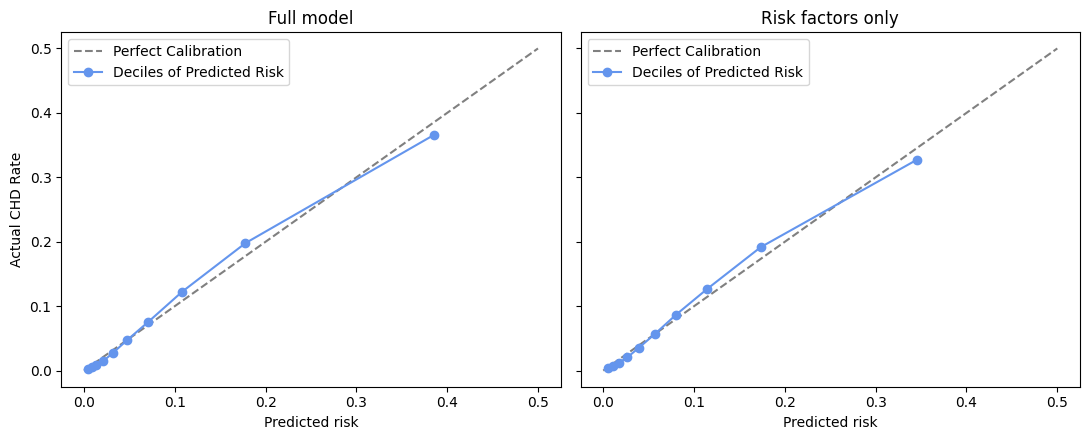

In [ ]:
# Calibration curve is one point per decile.
# If you're on the dashed line, you predict the actual rate
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, (name, tbl) in zip(axes, decile_tables.items()):
    ax.plot([0, 0.5],
        [0, 0.5],
        '--',
        label='Perfect Calibration',
        color='grey')
    ax.plot(tbl['predicted_risk'], tbl['actual_rate'], 'o-',
            color='cornflowerblue', label='Deciles of Predicted Risk')
    ax.set_title(name)
    ax.set_xlabel('Predicted risk')
    ax.legend(loc='upper left')

axes[0].set_ylabel('Actual CHD Rate')
plt.tight_layout()
plt.show()

As can be seen from the plots above, both models are well calibrated. In every decile the average predicted risk is within about 2 percentage points of the actual rate, and the curves follow the diagonal. The models slightly over predict at both ends and slightly under predict in between. The lowest groups are predicted a little higher than they turn out , deciles 8 and 9 are a little low, and the highest decile is a little high again.

## **Step 20:** Check Performance Across Groups

An overall score can hide a model that works well for some groups and poorly for others. This step compares both final models across **sex, age group and race/ethnicity** (race was left out of the model as an input and is used only here). For each group it reports:

- **Actual Rate** vs. **Predicted Risk:** Is the model well calibrated within the each group?
- **ROC-AUC:** Does the model rank people well within each group?
- **Recall** and **False Alarm Rate:** Using the 60% threshold of those with CHD, how many are flagged, and of those without CHD, how many are flagged anyway?

Predictions are the out-of-fold ones from Step 18. Differences in recall and false alarms between groups with different base rates are somewhat expected, because one cutoff is applied to everyone.

In [ ]:
# Metrics for one model, split by the values of one column of the raw data
def group_report(model_name, group_col):
    # raw_train has the original labels
    d = pd.DataFrame({'group': raw_train[group_col].values,
                      'actual': y_train.values,
                      'predicted': oof_probs[model_name]})

    # People flagged by the Step 18 cutoff for this model
    d['flagged'] = d['predicted'] >= thresholds[model_name]

    rows = []
    for g, part in d.groupby('group', observed=True):
        # People with CHD
        pos = part[part['actual'] == 1]

        # People without CHD
        neg = part[part['actual'] == 0]
        rows.append({'Group': g,
                     'People': len(part),
                     'Actual rate': part['actual'].mean(),
                     'Predicted risk': part['predicted'].mean(),
                     'ROC-AUC': roc_auc_score(part['actual'],
                                              part['predicted']),

                     # Share of positives flagged
                     'Recall': pos['flagged'].mean(),

                     # Share of negatives flagged
                     'False alarm rate': neg['flagged'].mean(),
                     'Share flagged': part['flagged'].mean()})

    return pd.DataFrame(rows).set_index('Group')

# Show the rates and ROC-AUC
def show(tbl):
    out = tbl.copy()
    for c in ['Actual rate',
              'Predicted risk',
              'Recall',
              'False alarm rate',
              'Share flagged']:
        out[c] = (out[c] * 100).round(1)
    out['ROC-AUC'] = out['ROC-AUC'].round(3)
    display(out)

for model_name in oof_probs:
    for col in ['Sex', 'AgeCategory', 'RaceEthnicityCategory']:
        print(f'\n{model_name} | {col}')
        show(group_report(model_name, col))


Full model | Sex


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate,Share flagged
Group,,,,,,,
Female,186312,6.9,6.9,0.839,50.8,9.6,12.4
Male,164471,10.8,10.8,0.842,66.7,17.7,23.0



Full model | AgeCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate,Share flagged
Group,,,,,,,
Age 18 to 24,21334,0.7,0.7,0.757,4.9,0.0,0.0
Age 25 to 29,17371,1.0,0.9,0.775,2.9,0.0,0.1
Age 30 to 34,20612,1.2,1.3,0.781,3.3,0.1,0.1
Age 35 to 39,22558,1.6,1.8,0.797,9.8,0.4,0.5
Age 40 to 44,23903,2.3,2.5,0.802,15.7,0.8,1.2
Age 45 to 49,22610,3.7,3.6,0.823,25.2,2.2,3.0
Age 50 to 54,26684,5.3,5.1,0.817,33.9,4.5,6.1
Age 55 to 59,29230,7.6,7.3,0.808,44.3,8.8,11.5
Age 60 to 64,35151,9.6,9.5,0.789,50.0,13.7,17.2



Full model | RaceEthnicityCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate,Share flagged
Group,,,,,,,
"Black only, Non-Hispanic",27843,7.3,9.0,0.827,59.2,15.1,18.4
Hispanic,33726,5.5,5.7,0.843,49.5,8.0,10.3
"Multiracial, Non-Hispanic",7525,8.5,7.8,0.863,61.6,11.2,15.5
"Other race only, Non-Hispanic",17901,6.3,6.3,0.875,56.5,8.3,11.3
"White only, Non-Hispanic",252867,9.4,9.2,0.842,60.9,14.3,18.6


... (2 outputs left out)


Risk factors only | AgeCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate,Share flagged
Group,,,,,,,
Age 18 to 24,21334,0.7,0.7,0.703,2.8,0.0,0.0
Age 25 to 29,17371,1.0,0.9,0.687,2.9,0.0,0.0
Age 30 to 34,20612,1.2,1.3,0.736,1.6,0.1,0.1
Age 35 to 39,22558,1.6,1.8,0.756,7.0,0.3,0.4
Age 40 to 44,23903,2.3,2.6,0.764,11.6,0.7,1.0
Age 45 to 49,22610,3.7,3.6,0.778,18.4,2.0,2.6
Age 50 to 54,26684,5.3,5.0,0.778,28.3,4.2,5.5
Age 55 to 59,29230,7.6,7.2,0.761,38.4,9.2,11.4
Age 60 to 64,35151,9.6,9.4,0.743,45.4,14.9,17.8



Risk factors only | RaceEthnicityCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate,Share flagged
Group,,,,,,,
"Black only, Non-Hispanic",27843,7.3,8.3,0.799,55.9,16.5,19.4
Hispanic,33726,5.5,5.5,0.825,46.8,9.0,11.1
"Multiracial, Non-Hispanic",7525,8.5,7.7,0.839,59.1,13.2,17.1
"Other race only, Non-Hispanic",17901,6.3,6.2,0.853,55.9,10.0,12.8
"White only, Non-Hispanic",252867,9.4,9.3,0.815,61.5,17.9,22.0


**Sex:** Both models are calibrated for each sex (predicted risk matches the actual rate: 6.9% for women and 10.8% for men) and rank equally well (ROC-AUC 0.839 vs. 0.842). The single cutoff treats the groups differently where it ranks ~67% of men and ~51% of women with CHD, and flags ~18% of healthy men but ~10% of healthy women. This result follows from the base rates, since men have a higher actual rate and so more of them cross the threshold.

**Age:** Calibration is good in every age group (within about 0.5 percentage points for the full model). The cutoff, however, behaves very differently by age where the full model catches ~5% of CHD cases at ages 18–24 but ~80% at 80 and older, while flagging about ~56% of all people aged 80 and older, half of whom (49.6%) are healthy. Within-group ranking is weaker than the overall ROC-AUC of 0.85 suggests (0.72–0.82), and weakest in the oldest group, so age explains much of the model's overall performance. A single threshold makes the model a screen for older people, and for younger people the predicted risks are well calibrated but too low to cross the cutoff.

**Race and Ethnicity:** Ranking quality is similar across groups (ROC-AUC ~0.83–0.88). Race is not an input, so this behavior arises through correlated features such as health status, diabetes and age.

## **Step 21:** Interpret the Models

There are two views of what each final model has learned:

1. **Odds Ratios with 95% Confidence Intervals:** An odds ratio of 2 means the odds of CHD double when the feature goes up by one unit, with the other features held fixed. Binary features compare yes with no, sex compares male with female, and numeric and ordered features are per one standard deviation. This info is an association, not a cause.
2. **Permutation Importance:** Shuffle one column in the held data and measure how much the ROC-AUC drops. A big drop means the model relies on that column.

Odds ratios come from refitting the same logistic regression with `statsmodels`, which gives confidence intervals (sklearn does not). On this much data the sklearn model's L2 penalty is tiny, and the coefficients match to within 0.006.

In [ ]:
import statsmodels.api as sm

final_models, odds_tables = {}, {}
for name, drop in final_sets.items():
    # Fit the final model on all training rows
    # (reused later for the test evaluation)
    model = make_model(LogisticRegression(max_iter=1000),
                       drop=drop).fit(X_train, y_train)
    final_models[name] = model

    # Training data after imputation and encoding, with readable column names
    names = [c.split('__', 1)[1]
             for c in model.named_steps['prep'].get_feature_names_out()]
    design = pd.DataFrame(model[:-1].transform(X_train),
                          columns=names,
                          index=X_train.index)

    # HadDiabetes has four levels; leave out 'No' so the other three are
    # compared with it (otherwise the columns are redundant with the intercept)
    design = design.drop(columns='HadDiabetes_No')

    # Same model, fitted with statsmodels to get confidence intervals
    fit = sm.Logit(y_train, sm.add_constant(design)).fit(disp=0)

    # 95% interval for each coefficient
    ci = fit.conf_int()
    odds_tables[name] = (pd.DataFrame({'Odds ratio': np.exp(fit.params),
                                       'Low': np.exp(ci[0]),
                                       'High': np.exp(ci[1]),
                                       'p-value': fit.pvalues})
                         .drop(index='const')
                         .sort_values('Odds ratio', ascending=False))

# Top 10 for each model
for name, tbl in odds_tables.items():
    print(name)
    display(tbl.head(10).round(3))

Full model


,Odds ratio,Low,High,p-value
HadStroke,2.550,2.448,2.657,0.000
AgeCategory,2.296,2.246,2.347,0.000
Sex,2.014,1.958,2.070,0.000
ChestScan,1.863,1.811,1.916,0.000
HadKidneyDisease,1.667,1.598,1.739,0.000
HadDiabetes_Yes,1.494,1.449,1.541,0.000
HadCOPD,1.472,1.418,1.528,0.000
"HadDiabetes_Yes, but only during pregnancy (female)",1.309,1.094,1.568,0.003
HadArthritis,1.214,1.180,1.249,0.000
LastCheckupTime,1.149,1.126,1.173,0.000


Risk factors only


,Odds ratio,Low,High,p-value
AgeCategory,2.565,2.511,2.621,0.000
Sex,2.171,2.113,2.230,0.000
HadKidneyDisease,2.087,2.003,2.175,0.000
HadCOPD,1.897,1.829,1.966,0.000
HadDiabetes_Yes,1.809,1.756,1.864,0.000
HadArthritis,1.418,1.379,1.457,0.000
BlindOrVisionDifficulty,1.358,1.298,1.419,0.000
"HadDiabetes_Yes, but only during pregnancy (female)",1.335,1.118,1.594,0.001
"HadDiabetes_No, pre-diabetes or borderline diabetes",1.226,1.139,1.319,0.000
HadDepressiveDisorder,1.219,1.177,1.263,0.000


In [ ]:
# Age and BMI are per standard deviation in the table above. Convert them to
# more natural units: per age group (5 years) and per 5 BMI points
sd_age = (OrdinalEncoder(categories=[ORDINAL['AgeCategory']])
          .fit_transform(train_filled[['AgeCategory']]).std())
sd_bmi = train_filled['BMI'].std()

for name, tbl in odds_tables.items():
    age = tbl.loc['AgeCategory', ['Odds ratio', 'Low', 'High']] ** (1 / sd_age)
    bmi = tbl.loc['BMI', ['Odds ratio', 'Low', 'High']] ** (5 / sd_bmi)
    print(f'{name}: per older age group {age.round(2).tolist()}, '
          f'per 5 BMI points {bmi.round(2).tolist()}')

Full model: per older age group [1.26, 1.25, 1.27], per 5 BMI points [1.03, 1.02, 1.04]
Risk factors only: per older age group [1.3, 1.29, 1.31], per 5 BMI points [1.06, 1.05, 1.07]


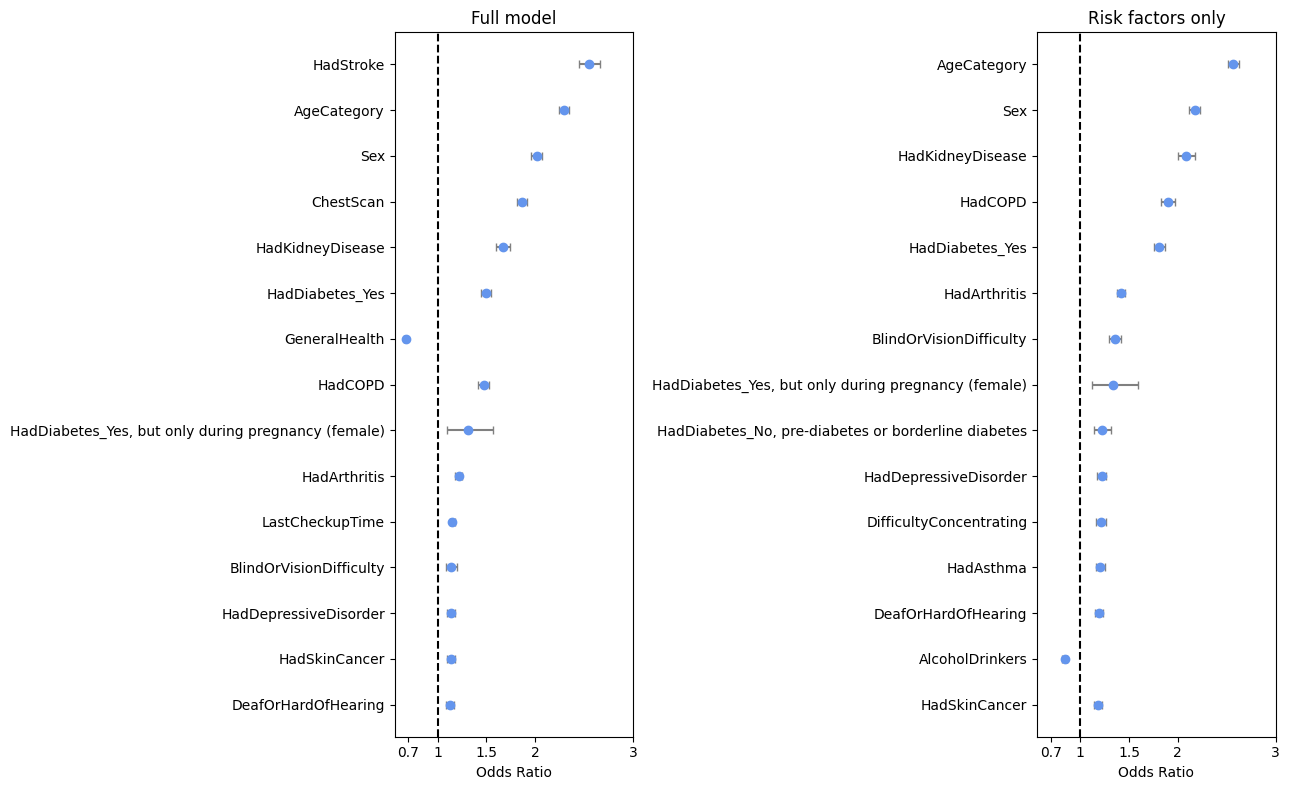

In [ ]:
# Forest plot: the 15 strongest effects for each model.
# The dot is the odds ratio, and the range is its 95% interval,
# and the dashed line at 1 means no effect.
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharex=True)
for ax, (name, tbl) in zip(axes, odds_tables.items()):

    # Strongest is the furthest from 1 in either direction
    t = tbl.assign(
        strength=np.abs(
            np.log(tbl['Odds ratio']))).sort_values('strength').tail(15)
    y = np.arange(len(t))
    ax.errorbar(t['Odds ratio'], y,
                xerr=[t['Odds ratio'] - t['Low'], t['High'] - t['Odds ratio']],
                fmt='o', color='cornflowerblue', ecolor='gray', capsize=3)
    ax.axvline(1, color='black', linestyle='--')
    ax.set_yticks(y)
    ax.set_yticklabels(t.index)
    ax.set_xticks([0.7, 1, 1.5, 2, 3])
    ax.set_xticklabels(['0.7', '1', '1.5', '2', '3'])
    ax.set_title(name)
    ax.set_xlabel('Odds Ratio')
plt.tight_layout()
plt.show()

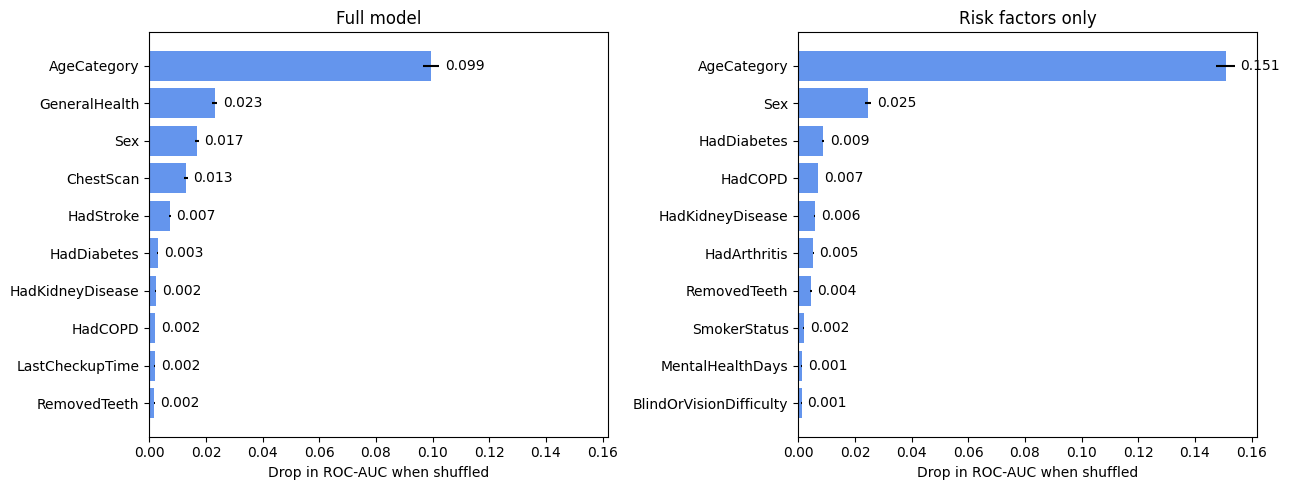

In [ ]:
from sklearn.inspection import permutation_importance

# Fit on 80% of the training set and shuffle columns in the other 20%
# (still training data, so the test set is not used)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

perm = {}
for name, drop in final_sets.items():
    m = make_model(
        LogisticRegression(max_iter=1000), drop=drop).fit(X_fit, y_fit)

    # Shuffle each column 5 times and record the average drop in ROC-AUC
    r = permutation_importance(m, X_val, y_val, scoring='roc_auc',
                               n_repeats=5, random_state=42, n_jobs=-1)

    # Keep only the columns this model actually uses
    kept = [c for c in X_train.columns if c not in drop]
    perm[name] = (pd.DataFrame({'drop': r.importances_mean,
                                'std': r.importances_std},
                               index=X_train.columns)
                  .loc[kept].sort_values('drop', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, (name, p) in zip(axes, perm.items()):
    # Reverse so the biggest is at the top
    top = p.head(10).iloc[::-1]
    bars = ax.barh(top.index,
                   top['drop'],
                   xerr=top['std'],
                   color='cornflowerblue')
    ax.bar_label(bars, fmt='%.3f', padding=4)
    ax.set_title(name)
    ax.set_xlabel('Drop in ROC-AUC when shuffled')
plt.tight_layout()
plt.show()

**Odds Ratios:** The strongest associations are consistent between the two models. Each older age group multiplies the odds of CHD by ~1.26 (full model) or ~1.3 (risk factors only), men have about twice the odds of women, and kidney disease, COPD, diabetes and arthritis are all associated with higher odds. In the full model the strongest features are a history of stroke (2.55). BMI has a small effect once the other features are fixed (1.03–1.04 per 5 points). Because the models contain many correlated health conditions, each odds ratio describes a feature with the others held fixed, so it is smaller than the raw rate difference seen in Step 11 and is an association, not a cause. Several confidence intervals are narrow (such as age and sex) because of the large sample, but the "diabetes only during pregnancy" estimate is wide (1.09–1.57) because that group is small.

**Permutation Importance:** Age dominates both models and shuffling it costs 0.099 ROC-AUC in the full model and 0.151 in the risk-factors-only model, far more than any other feature (the next largest are GeneralHealth 0.023 and Sex 0.017/0.025). The remaining features each contribute little individually (≤0.009 in the risk-factors-only model), which is why dropping many weak columns in Experiment 2 cost nothing in terms of model performance. Removing the consequence features (GeneralHealth, ChestScan, HadStroke) has the a strong impact on the model, as seen in Experiment 2 (three of the top five features in the full model are consequence features).

**What These Results Mean:** The model is essentially an age-and-sex ranking utility, refined by existing health conditions. Without the consequence features it relies more on age and on chronic conditions that are themselves heart-related (kidney disease, COPD, diabetes), so even the risk-factors-only model partially reflects existing CHD.

## **Step 22:** Final Evaluation on the Test Set

The test set (87,696 people, 8.7% with heart disease) has not been used for any decision so far. Both final models were fitted on all training rows (Step 21) and use the cutoffs chosen from out-of-fold training predictions (Step 18). This step scores them once, then repeats the calibration and fairness checks as a confirmation.

The 95% intervals come from resampling the test people 200 times. They show how much the scores depend on which people happened to land in the test set. The models are not refitted.

In [ ]:
from sklearn.metrics import (roc_auc_score,
                             average_precision_score,
                             brier_score_loss,
                             recall_score,
                             precision_score,
                             f1_score,
                             confusion_matrix)

# Original text labels, for the group checks later
raw_test = df.loc[X_test.index]
test_probs, rows = {}, []
rng = np.random.default_rng(42)

for name, model in final_models.items():
    # Predicted risk for every test person, and who the Step 18 cutoff flags
    p = model.predict_proba(X_test)[:, 1]
    test_probs[name] = p
    flagged = p >= thresholds[name]

    # Resample the test people with replacement 200 times to get 95% intervals
    boots = []
    for _ in range(200):
        i = rng.integers(0, len(y_test), len(y_test))
        boots.append((roc_auc_score(y_test.iloc[i], p[i]),
                      average_precision_score(y_test.iloc[i], p[i])))
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

    rows.append({'Model': name,
                 'ROC-AUC': round(roc_auc_score(y_test, p), 3),
                 'ROC-AUC 95% CI': f'{lo[0]:.3f}-{hi[0]:.3f}',
                 'PR-AUC': round(average_precision_score(y_test, p), 3),
                 'PR-AUC 95% CI': f'{lo[1]:.3f}-{hi[1]:.3f}',
                 'Brier': round(brier_score_loss(y_test, p), 3),
                 'Recall': round(recall_score(y_test, flagged), 3),
                 'Precision': round(precision_score(y_test, flagged), 3),
                 'F1': round(f1_score(y_test, flagged), 3),
                 'Share flagged': round(flagged.mean(), 3)})

display(pd.DataFrame(rows).set_index('Model'))

# Display reference values for always predicting the training set average
print('Dummy Brier:', round(brier_score_loss(y_test,
                                             np.full(len(y_test),
                                                     y_train.mean())),
                            3),
      '| PR-AUC of random guessing:', round(y_test.mean(), 3))

,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI,Brier,Recall,Precision,F1,Share flagged
Model,,,,,,,,,
Full model,0.847,0.842-0.850,0.359,0.349-0.370,0.066,0.597,0.298,0.398,0.174
Risk factors only,0.820,0.816-0.825,0.306,0.295-0.315,0.069,0.597,0.257,0.359,0.202


Dummy Brier: 0.079 | PR-AUC of random guessing: 0.087


In [ ]:
# What the cutoff does?
# How many people end up in each cell
for name, p in test_probs.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p >= thresholds[name]).ravel()
    print(f'{name}: caught {tp:,} of {tp + fn:,} cases; '
          f'false alarms {fp:,} of {fp + tn:,} healthy people; '
          f'{tp / (tp + fp):.1%} of those flagged have CHD')

Full model: caught 4,553 of 7,624 cases; false alarms 10,708 of 80,072 healthy people; 29.8% of those flagged have CHD
Risk factors only: caught 4,551 of 7,624 cases; false alarms 13,168 of 80,072 healthy people; 25.7% of those flagged have CHD


In [ ]:
# Calibration on the test set
# 10 equal groups by predicted risk (same as in Step 19)
for name, p in test_probs.items():
    d = pd.DataFrame({'predicted': p, 'actual': y_test.values})
    d['decile'] = pd.qcut(d['predicted'], 10, labels=False) + 1
    tbl = d.groupby('decile').agg(predicted_risk=('predicted', 'mean'),
                                  actual_rate=('actual', 'mean'))
    print(name)
    display((tbl * 100).round(1).T)

Full model


decile,1,2,3,4,5,6,7,8,9,10
predicted_risk,0.4,0.8,1.4,2.1,3.2,4.7,7.0,10.8,17.8,38.2
actual_rate,0.4,0.4,0.9,1.5,2.6,4.4,7.7,12.7,19.7,36.7


Risk factors only


decile,1,2,3,4,5,6,7,8,9,10
predicted_risk,0.6,1.0,1.7,2.6,3.9,5.7,8.0,11.5,17.3,34.4
actual_rate,0.5,0.6,1.4,2.0,3.4,5.6,8.8,13.1,19.1,32.5


In [ ]:
# Group check on the test set (same as in Step 20)
# (the group columns of interest)
def group_report_for(probs, y, raw, threshold, group_col):
    d = pd.DataFrame({'group': raw[group_col].values,
                      'actual': y.values,
                      'predicted': probs})
    d['flagged'] = d['predicted'] >= threshold

    out = []
    for g, part in d.groupby('group', observed=True):
        out.append({'Group': g, 'People': len(part),
                    'Actual rate': part['actual'].mean() * 100,
                    'Predicted risk': part['predicted'].mean() * 100,
                    'ROC-AUC': roc_auc_score(part['actual'], part['predicted']),
                    'Recall': part[part['actual'] == 1]['flagged'].mean() * 100,
         'False alarm rate': part[part['actual'] == 0]['flagged'].mean() * 100})
    return pd.DataFrame(out).set_index('Group').round(3)

for name in test_probs:
    for col in ['Sex', 'RaceEthnicityCategory']:
        print(f'\n{name} | {col}')
        display(group_report_for(test_probs[name],
                                 y_test,
                                 raw_test,
                                 thresholds[name],
                                 col))


Full model | Sex


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate
Group,,,,,,
Female,46468,6.805,6.867,0.842,50.791,9.717
Male,41228,10.823,10.643,0.843,66.047,17.679



Full model | RaceEthnicityCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate
Group,,,,,,
"Black only, Non-Hispanic",6975,7.269,8.907,0.835,62.525,15.476
Hispanic,8550,5.298,5.723,0.833,49.227,8.238
"Multiracial, Non-Hispanic",1872,8.921,7.979,0.872,66.467,10.733
"Other race only, Non-Hispanic",4407,6.013,6.270,0.880,57.736,8.281
"White only, Non-Hispanic",63268,9.463,9.162,0.845,60.314,14.247



Risk factors only | Sex


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate
Group,,,,,,
Female,46468,6.805,6.897,0.812,48.039,11.714
Male,41228,10.823,10.674,0.817,67.952,22.018



Risk factors only | RaceEthnicityCategory


,People,Actual rate,Predicted risk,ROC-AUC,Recall,False alarm rate
Group,,,,,,
"Black only, Non-Hispanic",6975,7.269,8.343,0.807,58.777,16.156
Hispanic,8550,5.298,5.595,0.811,46.578,9.287
"Multiracial, Non-Hispanic",1872,8.921,7.649,0.849,60.479,13.372
"Other race only, Non-Hispanic",4407,6.013,6.221,0.850,58.491,10.212
"White only, Non-Hispanic",63268,9.463,9.289,0.817,60.748,17.978


On the test data set the full model reaches ROC-AUC 0.847 (95% CI 0.842–0.850) and PR-AUC 0.359 (95% CI 0.349–0.370), which is ~4x the PR-AUC of random guessing (0.087). The risk-factors-only model reaches 0.820 (95% CI 0.816–0.825) and 0.306 (95% CI 0.295–0.315). Both are essentially identical to their cross-validation scores on the training data (0.845/0.354 and 0.819/0.303), so the model selection did not overfit the training data. Brier scores (0.066 and 0.069) are better than predicting the average for everyone (0.079).

At the cutoff chosen in Step 18, both models catch 59.7% of the people with CHD, as the 60% recall target intended. The full model flags 17.4% of people and 29.8% of them have CHD (3.4x the base rate); the risk-factors-only model flags 20.2% and is right 25.7% of the time. The extra information in the consequence features is worth ~4% of precision at the same recall.

Calibration is consistent on the test set as can be seen in every decile the average predicted risk is within 2 points of the actual rate, with the same slight pattern as in training (a little high in the lowest and highest groups, a little low in deciles 8–9). The group differences also repeat where calibration within the sex feature is good, a single cutoff gives higher recall and more false alarms for men than for women, and risk is overestimated for Black, Non-Hispanic people (8.9% predicted vs. 7.3% actual).

## Conclusions and Limitations

### What I found

- **Heart attack or angina can be predicted from survey answers with a meaningful ranking ability.** On the held-out test set, the full model reaches ROC-AUC 0.847 and PR-AUC 0.359 (random guessing gives 0.087). A model which leaves out features reflecting existing illness reaches 0.820 and 0.306 (i.e. a degradation in model performance).
- **The predicted probabilities can be read as potential risks.** In every decile of predicted risk, the average prediction is within about 2 points of the actual rate for both models in the training and test data sets. The top decile has an actual rate of about 37% against 0.4% in the bottom decile.
- **Model choice is not a factor.** Logistic Regression, Gradient Boosting, Random Forest, an MLP, and a CNN all fall within ~0.003 ROC-AUC of each other, so the simplest and most interpretable one (**Logistic Regression**) was chosen for the final model. The CNN also scored the same with shuffled column order, which confirms that the columns have no order for it to use to improve the prediction.
- **The experiments settled the final model design choices.** Class weights and resampling raised recall but pushed the Brier score from 0.066 to about 0.165, so the threshold is chosen after instead. I also found that median/mode imputation was enough. I also found that missing-value flags changed ROC-AUC by at most 0.002. Dropping height, weight, state, race and six weak features had no negative impact on the model performance.
- **What drives the predictions?** Age drives performance by a wide margin (permutation importance 0.099 for the full model and 0.15 for the risk-factors-only model, versus at most 0.03 for anything else), then sex, and finally existing conditions: stroke, kidney disease, COPD, diabetes and arthritis. Each older age group multiplies the odds by about 1.3, and men have about twice the odds over women.
- **The models behave as expected on new unseen data.** Test scores match cross-validation (0.847 vs. 0.845 ROC-AUC for the full model), so model selection did not overfit the training data.

### Is the model useful?

It is useful for **ranking people by risk and for producing calibrated probabilities**. It is not a diagnostic tool, however. At the chosen cutoff (60% recall), only about 30% of flagged people have CHD (26% for the risk-factors-only model), 40% of cases are missed, and the full model raises ~10,700 false alarms for ~4,500 true catches. That could support deciding who to medically evaluate first, but not who is sick.

### Limitations

- **Self-reported, cross-sectional data.** The survey records whether someone has had a heart attack or angina, so the models describe existing CHD, not future risk, and answers depend on what people remember and report. Odds ratios are associations, not causes.
- **Reverse causality.** General health, chest scan, stroke history, difficulty walking and similar features partly reflect illness that is already present. They add about 0.025 ROC-AUC, which is why the risk-factors-only is reported alongside the full model. The model already includes conditions such as kidney disease and COPD that are themselves linked to CHD.                                             - **Age is the most important feature in terms of model prediction.** Within an age group the models rank people less well (ROC-AUC 0.72–0.82 for the full model), and the weakest results are at the youngest and oldest ages. A single threshold flags mostly older people with about 57% of people aged '80 and older' are flagged (half of them healthy) while the youngest ages are almost never flagged.
- **Group differences.** Calibration is good within each sex, but one cutoff gives higher recall and more false alarms for men than for women. Risk is overestimated for Black, Non-Hispanic respondents (8.9% predicted vs. 7.3% actual) even though race is not an input, so the model picks it up through correlated features.
- **One survey year, one population.** The data are the 2022 BRFSS for U.S. adults. Nothing here shows how the models would perform in another year, another country, or even within a particular clinic. External validation would be needed before any real use.
- **Some choices were judgment calls.** The 60% recall target for the threshold, the exclusion of race as an input, and the choice to report two models are all decisions that could reasonably be argued be changed.
- **Subsamples for two models.** KNN and the RBF SVM were run on stratified subsamples (80,000 and 30,000 rows) because the run times became excessive using all the training row data, so their scores are not directly comparable with the other models.

### Possible next steps

- Compare with a baseline using age and sex only, to measure what the other features add beyond demographics.
- Validate on another BRFSS year, or on clinical data where CHD is measured and not self-reported.